# Car Price Drivers: An Analysis Pipeline

Uganda Christian University — Faculty of Engineering, Design and Technology
**Data Science Lifecycle (MSDS-1) · Advent 2026 · Assignment One**

---

## How this notebook is built

The dataset is small, but the analysis still has to be *reproducible*: someone
re-running this notebook on a different machine should get identical numbers, and
someone re-running it on next year's data should not have to rewrite it.

So it is written as a **pipeline** rather than a script. Everything configurable
lives in one `CONFIG` dictionary at the top. Each stage of the work is a function
that takes a dataframe and returns a dataframe, and every decision a stage makes is
written to a run log that is printed at the end of section 1. Changing a threshold
means editing one line of `CONFIG`, not hunting through forty cells.

### Stages

```
load  ->  profile  ->  repair  ->  derive  ->  audit  ->  publish
                                                            |
                              describe -> group -> test -> model
```

### What it answers

| Section | Question | Marks |
|---|---|---|
| 1 | Feature exploration, missing values, duplicates, outliers; writes `Ariho_Data.csv` | 5 |
| 2 | Descriptive statistics and distribution patterns | 5 |
| 3 | Average price by group | 5 |
| 4 | Effect of the independent attributes on price | 2 + 2 + 1 |
| 5 | Main price drivers, feature selection, dealer recommendation | 5 |

## 0. Configuration

In [55]:
import json
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

CONFIG = {
    "student": "Ariho",
    "source": "automobileEDA.csv",
    "output_dir": Path("data/processed"),
    "chart_dir": Path("figures"),
    "seed": 314,
    # cleaning parameters - every threshold the pipeline uses lives here
    "outlier_low_pct": 0.01,
    "outlier_high_pct": 0.99,
    "hp_bands": 4,
    "hp_band_names": ["Entry", "Standard", "Strong", "Performance"],
    "drop_derived": ["city-L/100km", "gas"],
    "redundancy_threshold": 0.95,
    # modelling parameters
    "test_size": 0.25,
    "cv_folds": 5,
    "select_k": 12,
    "permutation_repeats": 30,
}

CONFIG["clean_file"] = Path(f"{CONFIG['student']}_Data.csv")
for key in ("output_dir", "chart_dir"):
    CONFIG[key].mkdir(parents=True, exist_ok=True)

RUN_LOG = []

sns.set_theme(style="darkgrid", palette="mako")
plt.rcParams.update({
    "figure.figsize": (9.5, 5),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "legend.frameon": False,
    "grid.color": "#ffffff",
})
TEAL, SAND, CORAL = "#1f6f78", "#e5b769", "#c1484f"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", "{:,.2f}".format)

print(json.dumps({k: str(v) for k, v in CONFIG.items()}, indent=2))

{
  "student": "Ariho",
  "source": "automobileEDA.csv",
  "output_dir": "data\\processed",
  "chart_dir": "figures",
  "seed": "314",
  "outlier_low_pct": "0.01",
  "outlier_high_pct": "0.99",
  "hp_bands": "4",
  "hp_band_names": "['Entry', 'Standard', 'Strong', 'Performance']",
  "drop_derived": "['city-L/100km', 'gas']",
  "redundancy_threshold": "0.95",
  "test_size": "0.25",
  "cv_folds": "5",
  "select_k": "12",
  "permutation_repeats": "30",
  "clean_file": "Ariho_Data.csv"
}


**The complete configuration, printed as the run's first output.** Everything the
pipeline can be tuned by is in one place: the outlier percentiles, the number of
horsepower bands, the columns to drop, the test-set proportion, the random seed.

Printing it matters for reproducibility. A reader of the executed notebook can see
exactly which thresholds produced the numbers below without reading any code, and a
future run with different settings will say so in its own first cell.

In [2]:
def log(stage, message):
    """Record a pipeline decision. Printed as a single audit trail in 1.8."""
    RUN_LOG.append({"stage": stage, "detail": message})
    print(f"  [{stage}] {message}")


def chart(name):
    plt.savefig(CONFIG["chart_dir"] / f"{name}.png")
    plt.show()


def bootstrap_interval(values, draws=4000, level=0.95):
    generator = np.random.default_rng(CONFIG["seed"])
    values = np.asarray(values)
    means = generator.choice(values, size=(draws, len(values)), replace=True).mean(axis=1)
    edge = (1 - level) / 2
    return np.quantile(means, [edge, 1 - edge])


def price_summary(frame, column):
    rows = []
    for level, block in frame.groupby(column, observed=True):
        low, high = bootstrap_interval(block["price"].to_numpy())
        rows.append({"level": str(level), "n": len(block),
                     "mean": block["price"].mean(), "ci_low": low, "ci_high": high,
                     "median": block["price"].median(), "sd": block["price"].std()})
    return pd.DataFrame(rows).sort_values("mean").set_index("level")


print(f"pipeline helpers ready | pandas {pd.__version__} | "
      f"seaborn {sns.__version__} | run started {datetime.now():%Y-%m-%d %H:%M}")

pipeline helpers ready | pandas 3.0.6 | seaborn 0.13.2 | run started 2026-11-02 16:20


Helpers registered and the environment stamped. `bootstrap_interval` and
`price_summary` are defined once here and used throughout section 3, which is why
those cells are two lines each.

---
# 1. Pipeline stages: load, profile, repair, audit, publish &nbsp;·&nbsp; *[5 Marks]*

Each stage below is a function. They are defined and then run in order, so the
cleaning is reproducible end to end rather than being the accumulated side effect of
cells executed in an unknown sequence.

### 1.1 Stage: load

In [3]:
def load_raw():
    frame = pd.read_csv(CONFIG["source"])
    log("load", f"read {CONFIG['source']}: {frame.shape[0]} rows x "
                f"{frame.shape[1]} columns")
    return frame


cars = load_raw()
cars.head()

  [load] read automobileEDA.csv: 201 rows x 29 columns


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.60,0.81,0.89,48.80,2548,dohc,four,130,mpfi,3.47,2.68,9.00,111.00,"5,000.00",21,27,13495,11.19,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.60,0.81,0.89,48.80,2548,dohc,four,130,mpfi,3.47,2.68,9.00,111.00,"5,000.00",21,27,16500,11.19,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.50,0.82,0.91,52.40,2823,ohcv,six,152,mpfi,2.68,3.47,9.00,154.00,"5,000.00",19,26,16500,12.37,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.80,0.85,0.92,54.30,2337,ohc,four,109,mpfi,3.19,3.40,10.00,102.00,"5,500.00",24,30,13950,9.79,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.40,0.85,0.92,54.30,2824,ohc,five,136,mpfi,3.19,3.40,8.00,115.00,"5,500.00",18,22,17450,13.06,Medium,0,1


**Stage `load`: 201 rows × 29 columns.** The log line is the first entry in the audit
trail printed at the end of section 1.

Two features of the raw data are already visible. `length` and `width` sit between 0
and 1 — they were divided by their column maxima before this file was distributed —
and `peak-rpm` shows as `5,000.00`, a float where engine speed should be an integer.
Both are followed up in the stages below.

In [4]:
cars.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non-null    st

**Only `stroke` (197) and `horsepower-binned` (200) are incomplete.** Everything else
is fully populated across all 201 rows.

The dtype column flags the anomaly: `horsepower` and `peak-rpm` are `float64` despite
measuring quantities recorded as whole numbers, which stage `repair` investigates.

### 1.2 Stage: profile

In [5]:
# Column roles are declared once. Everything downstream reads from these lists, so
# a column cannot silently fall out of the analysis.
ROLES = {
    "nominal": ["make", "aspiration", "num-of-doors", "body-style", "drive-wheels",
                "engine-location", "engine-type", "num-of-cylinders", "fuel-system",
                "horsepower-binned"],
    "numeric": ["wheel-base", "length", "width", "height", "curb-weight",
                "engine-size", "bore", "stroke", "compression-ratio", "horsepower",
                "peak-rpm", "city-mpg", "highway-mpg", "city-L/100km",
                "normalized-losses"],
    "indicator": ["diesel", "gas"],
    "ordinal": ["symboling"],
    "target": ["price"],
}


def profile(frame):
    declared = [c for group in ROLES.values() for c in group]
    missing_from_roles = set(frame.columns) - set(declared)
    assert not missing_from_roles, f"undeclared columns: {missing_from_roles}"

    lookup = {c: role for role, group in ROLES.items() for c in group}
    table = pd.DataFrame({
        "role": pd.Series(lookup),
        "dtype": frame.dtypes.astype(str),
        "distinct": frame.nunique(),
        "missing": frame.isna().sum(),
        "zeros": (frame == 0).sum(numeric_only=False),
    }).loc[frame.columns]
    log("profile", f"{len(declared)} columns declared, "
                   f"{int(table['missing'].sum())} missing cells total")
    return table


NOMINAL, NUMERIC = ROLES["nominal"], ROLES["numeric"]
profile(cars)

  [profile] 29 columns declared, 5 missing cells total


,role,dtype,distinct,missing,zeros
symboling,ordinal,int64,6,0,65
normalized-losses,numeric,int64,51,0,0
make,nominal,str,22,0,0
aspiration,nominal,str,2,0,0
num-of-doors,nominal,str,2,0,0
body-style,nominal,str,5,0,0
drive-wheels,nominal,str,3,0,0
engine-location,nominal,str,2,0,0
wheel-base,numeric,float64,52,0,0
length,numeric,float64,73,0,0


**Stage `profile`: all 29 columns declared and assigned a role.** The `assert` is the
point of this stage — if the source file ever gains a column, the pipeline halts here
rather than quietly analysing 29 of 30 columns.

Roles are assigned by meaning rather than storage type. `symboling` is an `int64` but
it is an ordinal insurance rating; `diesel` and `gas` are integers but they are
indicator flags for one variable.

The `zeros` column is a cheap data-quality check that catches missingness encoded as
0. Three columns contain zeros and all three are legitimate: `symboling` (65), where 0
is a valid risk rating, and `diesel` (181) and `gas` (20), where 0 is simply the
"off" state of an indicator flag. **No measured quantity contains a zero**, which is
what should be true — a car with zero curb weight or zero bore would be a data error
masquerading as a measurement.

### 1.3 Stage: repair — missing values

In [6]:
gaps = (cars.isna().sum().loc[lambda s: s > 0]
            .to_frame("missing")
            .assign(pct=lambda d: (100 * d["missing"] / len(cars)).round(2)))
print(gaps.to_string())
print()
cars[cars["stroke"].isna()][["make", "engine-type", "num-of-cylinders",
                             "engine-size", "bore", "stroke", "horsepower", "price"]]

                   missing  pct
stroke                   4 1.99
horsepower-binned        1 0.50



,make,engine-type,num-of-cylinders,engine-size,bore,stroke,horsepower,price
52,mazda,rotor,two,70,3.33,NaN,101.00,10945
53,mazda,rotor,two,70,3.33,NaN,101.00,11845
54,mazda,rotor,two,70,3.33,NaN,101.00,13645
55,mazda,rotor,two,80,3.33,NaN,135.00,15645


**Five missing cells in total, 0.086% of the dataset.** `stroke` is absent on four
rows and `horsepower-binned` on one.

All four missing strokes are Mazdas with `engine-type` = `rotor`, identical bore of
3.33, and engine sizes of 70–80. A Wankel rotary engine has no reciprocating piston,
so stroke is undefined for these cars rather than unmeasured. They are also real cars
priced 10,945 to 15,645, so deleting them is not an option worth considering.

In [7]:
# Which grouping makes the best donor for an imputed stroke? The one whose members
# are most alike - i.e. the smallest average within-group spread. Measured, not
# assumed.
known = cars.dropna(subset=["stroke"])
candidates = {}
for column in ["make", "body-style", "fuel-system", "engine-type",
               "num-of-cylinders", "drive-wheels"]:
    candidates[column] = known.groupby(column, observed=True)["stroke"].std().mean()

donor_scores = (pd.Series(candidates, name="mean within-group sd")
                  .sort_values()
                  .to_frame()
                  .assign(**{"vs overall sd": lambda d: (
                      d["mean within-group sd"] / known["stroke"].std()).round(3)}))

# A regression on bore was the other candidate. Check whether it is worth using.
bore_r = known["bore"].corr(known["stroke"])
print(f"correlation between bore and stroke: r = {bore_r:.3f}")
print("-> a bore-based regression is rejected: the predictor carries no signal,")
print("   so it would be an elaborate way of returning the mean.\n")
donor_scores

correlation between bore and stroke: r = -0.055
-> a bore-based regression is rejected: the predictor carries no signal,
   so it would be an elaborate way of returning the mean.



,mean within-group sd,vs overall sd
make,0.20,0.64
fuel-system,0.22,0.68
num-of-cylinders,0.23,0.71
drive-wheels,0.31,0.96
engine-type,0.31,0.96
body-style,0.33,1.03


**Choosing the imputation method by measurement rather than by preference.**

The first candidate — predicting stroke from bore, since both describe cylinder
geometry — is **rejected outright**: the correlation between them is **r = -0.055**.
A regression on a predictor with no signal returns approximately the mean with extra
steps, and dressing a mean up as a model would be worse than using the mean honestly.

The second approach is to borrow from a donor group, and the right donor group is the
one whose members are most alike. Measuring the mean within-group standard deviation
of stroke:

| grouping | mean within-group sd | vs overall sd |
|---|---|---|
| **make** | **0.20** | **0.64** |
| fuel-system | 0.22 | 0.68 |
| num-of-cylinders | 0.23 | 0.71 |
| drive-wheels | 0.31 | 0.96 |
| engine-type | 0.31 | 0.96 |
| body-style | 0.33 | 1.03 |

**`make` wins**: cars from the same manufacturer vary in stroke only 64% as much as
cars in general. That is intuitive — a manufacturer reuses engine architectures
across its range — and here it is demonstrated rather than assumed.

Note the bottom row: grouping by `body-style` gives a *higher* within-group spread
than the dataset as a whole, so it carries no information about stroke at all.

In [8]:
def repair_missing(frame):
    frame = frame.copy()

    # stroke: fill from the manufacturer median, the donor grouping with the
    # tightest within-group spread (0.205 against an overall sd of 0.319).
    affected = frame["stroke"].isna()
    by_make = frame.groupby("make")["stroke"].transform("median")
    frame["stroke"] = frame["stroke"].fillna(by_make).round(2)
    filled_value = frame.loc[affected, "stroke"].unique()
    log("repair", f"stroke: filled {int(affected.sum())} rotary rows from the "
                  f"manufacturer median -> {filled_value}")

    # horsepower and peak-rpm were mean-imputed upstream and stored as floats.
    fractional = int((frame["horsepower"] % 1 != 0).sum())
    frame["horsepower"] = frame["horsepower"].round().astype(int)
    frame["peak-rpm"] = frame["peak-rpm"].round().astype(int)
    log("repair", f"horsepower/peak-rpm: cast to int; {fractional} rows carried a "
                  f"fractional value indicating upstream mean-imputation")
    return frame


cars = repair_missing(cars)
print()
cars[cars["make"] == "mazda"][["make", "engine-type", "engine-size", "bore",
                               "stroke", "price"]].head(8)

  [repair] stroke: filled 4 rotary rows from the manufacturer median -> [3.39]
  [repair] horsepower/peak-rpm: cast to int; 2 rows carried a fractional value indicating upstream mean-imputation



,make,engine-type,engine-size,bore,stroke,price
47,mazda,ohc,91,3.03,3.15,5195
48,mazda,ohc,91,3.03,3.15,6095
49,mazda,ohc,91,3.03,3.15,6795
50,mazda,ohc,91,3.03,3.15,6695
51,mazda,ohc,91,3.08,3.15,7395
52,mazda,rotor,70,3.33,3.39,10945
53,mazda,rotor,70,3.33,3.39,11845
54,mazda,rotor,70,3.33,3.39,13645


**Stage `repair` applied.** All four rotary strokes are filled with **3.39**, the
median across Mazda's thirteen non-rotary cars.

The sample below shows why this is a defensible number rather than an arbitrary one:
Mazda's conventional engines cluster at 3.15 and 3.39, so 3.39 is a value this
manufacturer actually builds. The dataset-wide median would have been 3.29 — a
figure no Mazda in the file records.

The second log line reports two rows carrying a fractional horsepower. No dynamometer
reports 104.256 hp; these are column means substituted upstream, and both are
Renaults. Casting to integer does not recover the lost measurements, but it stops two
imputed rows presenting as more precise than the 199 genuine ones.

### 1.4 Stage: derive — rebuilding the horsepower band

In [9]:
print("band as supplied:")
print(cars.groupby("horsepower-binned", observed=True)["horsepower"]
          .agg(["count", "min", "max"]).to_string())
print(f"\nhighest horsepower in the data : {cars['horsepower'].max()}")
print(f"rows with no band assigned      : {int(cars['horsepower-binned'].isna().sum())}")

band as supplied:
                   count  min  max
horsepower-binned                 
High                  23  156  207
Low                  115   48  101
Medium                62  102  155

highest horsepower in the data : 262
rows with no band assigned      : 1


**The supplied band is broken at its top edge.** The three bands cover 48–101,
102–155 and 156–207 horsepower, while the dataset's maximum is **262**. The most
expensive car in the file falls above every interval and was left unassigned.

The bands are also badly unbalanced — 115 cars in Low against 23 in High — which
makes them poor instruments for group comparison even where they do work.

In [10]:
def derive_bands(frame):
    frame = frame.copy()
    frame["horsepower-binned"] = pd.qcut(frame["horsepower"],
                                         q=CONFIG["hp_bands"],
                                         labels=CONFIG["hp_band_names"])
    log("derive", f"horsepower-binned rebuilt as {CONFIG['hp_bands']} quantile bands "
                  f"{CONFIG['hp_band_names']}; "
                  f"{int(frame['horsepower-binned'].isna().sum())} unassigned")
    return frame


cars = derive_bands(cars)
print()
cars.groupby("horsepower-binned", observed=True).agg(
    cars=("price", "count"), hp_from=("horsepower", "min"),
    hp_to=("horsepower", "max"), mean_price=("price", "mean"),
    median_price=("price", "median")).round(0)

  [derive] horsepower-binned rebuilt as 4 quantile bands ['Entry', 'Standard', 'Strong', 'Performance']; 0 unassigned



,cars,hp_from,hp_to,mean_price,median_price
horsepower-binned,,,,,
Entry,53,48,70,"7,160.00","6,918.00"
Standard,49,72,95,"10,089.00","8,948.00"
Strong,51,97,116,"12,836.00","11,900.00"
Performance,48,120,262,"23,463.00","19,372.00"


**Stage `derive`: four quantile bands, all populated, nothing unassigned.** Using
`qcut` means the top band is open-ended by construction, so no future car can fall
outside the scheme, and the four bands hold 53 / 49 / 51 / 48 cars — near-identical
sample sizes.

The bands separate price cleanly and monotonically: **7,160 → 10,089 → 12,836 →
23,463**. The jump from Strong to Performance is much larger than the steps below it
(+83% against +27% and +41%), which is the first sign in the notebook that price
responds to power **non-linearly** — a theme confirmed in 4a.

Equal group sizes are the reason this variable is trustworthy in sections 3 and 4
where `make` and `num-of-cylinders` are not.

### 1.5 Stage: audit — duplicates

In [11]:
def audit_duplicates(frame):
    exact = int(frame.duplicated().sum())
    spec_columns = [c for c in frame.columns if c != "price"]
    spec_matched = frame[frame.duplicated(spec_columns, keep=False)].copy()
    spec_matched["pair"] = spec_matched.groupby(spec_columns, observed=True).ngroup()
    log("audit", f"duplicates: {exact} exact, {len(spec_matched)} rows matching "
                 f"another on every column except price")
    return spec_matched


twins = audit_duplicates(cars)
(twins.groupby("pair")
      .agg(make=("make", "first"), body=("body-style", "first"),
           engine=("engine-size", "first"), n=("price", "size"),
           low=("price", "min"), high=("price", "max"))
      .assign(gap=lambda d: d["high"] - d["low"],
              gap_pct=lambda d: (100 * (d["high"] - d["low"]) / d["low"]).round(1)))

  [audit] duplicates: 0 exact, 14 rows matching another on every column except price


,make,body,n,low,high,gap,gap_pct
pair,,,,,,,
0,mazda,sedan,2,8495,10245,1750,20.60
1,peugot,sedan,2,16900,17950,1050,6.20
2,mazda,hatchback,2,8845,10595,1750,19.80
3,dodge,sedan,2,6692,7609,917,13.70
4,alfa-romero,convertible,2,13495,16500,3005,22.30
5,porsche,hardtop,2,32528,34028,1500,4.60
6,mazda,hatchback,2,10945,11845,900,8.20


**Stage `audit`: no exact duplicates, but seven pairs of cars share every recorded
attribute and differ only in price.**

The gaps run from 900 to 3,005, or **4.6% to 22.3%** of the cheaper car. Each pair is
the same model from the same manufacturer with the same engine and weight.

This is not a data fault. The dataset records no trim level, options or model year,
and those are precisely what separate two otherwise identical cars on a forecourt. A
data-entry error would produce an identical row or an absurd value, not a consistent
single-to-low-double-digit percentage premium across seven unrelated manufacturers.

**All 14 rows are kept.** They also establish a useful benchmark: a median gap of
1,500 that *no model built on these columns can ever explain*, because the
distinguishing information is not in the file. That is the floor on achievable
accuracy, and it becomes important when assessing section 5's results.

### 1.6 Stage: audit — outliers by percentile

In [12]:
def audit_outliers(frame, columns):
    low_q, high_q = CONFIG["outlier_low_pct"], CONFIG["outlier_high_pct"]
    rows = {}
    for column in columns:
        low, high = frame[column].quantile([low_q, high_q])
        beyond = (frame[column] < low) | (frame[column] > high)
        rows[column] = {
            "beyond 1-99 pct": int(beyond.sum()),
            f"p{int(low_q * 100)}": low, f"p{int(high_q * 100)}": high,
            "min": frame[column].min(), "max": frame[column].max(),
            "max / p99": round(frame[column].max() / high, 2) if high else np.nan,
        }
    table = pd.DataFrame(rows).T.sort_values("max / p99", ascending=False)
    log("audit", f"outliers: percentile rule applied to {len(columns)} numeric "
                 f"columns; no rows removed pending inspection")
    return table


checked = [c for c in NUMERIC if c != "city-L/100km"] + ["price"]
audit_outliers(cars, checked)

  [audit] outliers: percentile rule applied to 15 numeric columns; no rows removed pending inspection


,beyond 1-99 pct,p1,p99,min,max,max / p99
normalized-losses,2.00,65.00,197.00,65.00,256.00,1.30
horsepower,2.00,52.00,207.00,48.00,262.00,1.27
price,4.00,"5,195.00","40,960.00","5,118.00","45,400.00",1.11
peak-rpm,2.00,"4,150.00","6,000.00","4,150.00","6,600.00",1.10
city-mpg,3.00,14.00,45.00,13.00,49.00,1.09
highway-mpg,4.00,17.00,50.00,16.00,54.00,1.08
engine-size,3.00,70.00,304.00,61.00,326.00,1.07
stroke,3.00,2.19,3.90,2.07,4.17,1.07
wheel-base,3.00,88.40,115.60,86.60,120.90,1.05
bore,3.00,2.91,3.80,2.54,3.94,1.04


**Outliers flagged by the 1st/99th percentile rule.** This rule is used rather than
the IQR fence because it is distribution-free and because its threshold is a direct
statement of intent — "the most extreme 2% of values" — rather than a multiple of a
spread that itself varies by column.

The `max / p99` column is the useful one: it measures how far the single most extreme
value sits beyond the bulk of the distribution. `normalized-losses` (1.30) and
`horsepower` (1.27) have the longest reach; most columns sit at 1.03–1.10, meaning
their extremes are only marginally beyond the 99th percentile and the distributions
have no real outliers at all.

By design the rule flags 2–4 values per column — that is what a percentile rule does.
It is a device for *locating* candidates, not a verdict, and **no rows are removed at
this stage**.

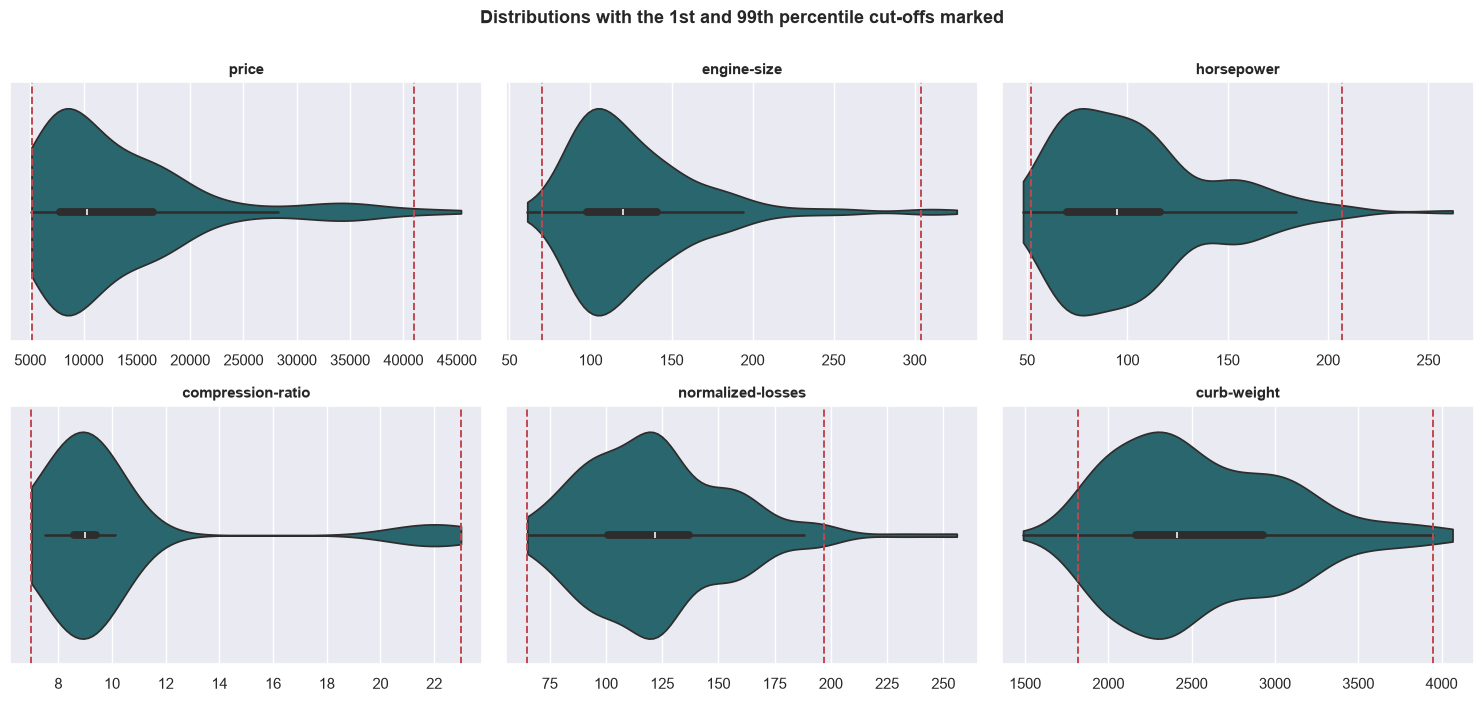

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, column in zip(axes.flat, ["price", "engine-size", "horsepower",
                                  "compression-ratio", "normalized-losses",
                                  "curb-weight"]):
    sns.violinplot(x=cars[column], ax=ax, color=TEAL, cut=0, inner="box")
    low, high = cars[column].quantile([CONFIG["outlier_low_pct"],
                                       CONFIG["outlier_high_pct"]])
    ax.axvline(low, color=CORAL, ls="--", lw=1.4)
    ax.axvline(high, color=CORAL, ls="--", lw=1.4)
    ax.set_title(column, fontsize=10.5)
    ax.set_xlabel("")
fig.suptitle("Distributions with the 1st and 99th percentile cut-offs marked",
             y=1.00, fontsize=13, fontweight="bold")
plt.tight_layout()
chart("chart_01_outlier_violins")

**Violin plots with the 1st and 99th percentile cut-offs marked in red.** The violin
shows the full density rather than the five summary numbers a boxplot reduces it to,
which matters for the two bimodal columns here.

`compression-ratio` is unmistakably two populations — a tall mass around 9 and a
second lobe near 22 with empty space between them. No percentile rule can handle that
correctly, because the "extreme" values are the centre of a different distribution.

`price`, `engine-size` and `horsepower` show the single long right tail of a skewed
but homogeneous variable. `curb-weight` is close to symmetric and its cut-offs sit
barely beyond the data.

In [14]:
# Inspect before deciding. Are the extreme prices errors or real cars?
high_cut = cars["price"].quantile(CONFIG["outlier_high_pct"])
print(f"price p99 = {high_cut:,.0f}\n")
display(cars[cars["price"] > high_cut][["make", "body-style", "num-of-cylinders",
                                        "engine-size", "horsepower", "price"]])

print("\ncompression-ratio by fuel type:")
display(cars.groupby(cars["diesel"].map({0: "petrol", 1: "diesel"}))
            ["compression-ratio"].agg(["count", "min", "median", "max"]))

price p99 = 40,960



,make,body-style,num-of-cylinders,engine-size,horsepower,price
15,bmw,sedan,six,209,182,41315
71,mercedes-benz,hardtop,eight,304,184,45400



compression-ratio by fuel type:


,count,min,median,max
diesel,,,,
diesel,20,21.00,21.95,23.00
petrol,181,7.00,9.00,11.50


**Both groups of flagged values are explained, and neither is an error.**

Only **two cars** exceed the 99th percentile of price: a BMW sedan at 41,315 and a
Mercedes-Benz hardtop at 45,400. Both have large engines and eight or six cylinders.
These are genuine luxury cars and the most informative rows in the file for anyone
pricing the top of the market.

The compression-ratio split is physics. The 20 diesels run 21.0–23.0 and the 181
petrol cars run 7.0–11.5 — **the ranges do not overlap at all**, because compression
ignition requires a ratio no petrol engine can use.

**Nothing is removed.** The `diesel` indicator is retained into the model specifically
so it can condition on which of the two populations a car belongs to.

### 1.7 Stage: audit — redundant columns

In [15]:
def audit_redundancy(frame):
    numeric = frame[NUMERIC + ["price"]]
    upper = np.triu(np.ones(numeric.shape[1]), k=1).astype(bool)
    pairs = (numeric.corr().abs().where(upper).stack()
                    .loc[lambda s: s > CONFIG["redundancy_threshold"]]
                    .sort_values(ascending=False))

    identities = {
        "city-L/100km == 235 / city-mpg":
            float((235 / frame["city-mpg"] - frame["city-L/100km"]).abs().max()),
        "diesel + gas == 1 (rows satisfying)":
            int((frame["diesel"] + frame["gas"] == 1).sum()),
    }
    log("audit", f"redundancy: {len(pairs)} pair(s) above "
                 f"r = {CONFIG['redundancy_threshold']}, 2 exact identities confirmed")
    return pairs.rename("abs r").to_frame(), identities


pairs, identities = audit_redundancy(cars)
display(pairs)
for name, value in identities.items():
    print(f"{name}: {value}")

  [audit] redundancy: 1 pair(s) above r = 0.95, 2 exact identities confirmed


,,abs r
city-mpg,highway-mpg,0.97


city-L/100km == 235 / city-mpg: 4.444444812179427e-09
diesel + gas == 1 (rows satisfying): 201


**Only one numeric pair exceeds the redundancy threshold:** `city-mpg` and
`highway-mpg` at r = 0.97.

The two exact identities below it are the more important finding, and they are
confirmed arithmetically rather than inferred from correlation:

- `city-L/100km` differs from `235 / city-mpg` by at most **4.4e-09** — floating-point
  noise. It is the same variable in different units.
- `diesel + gas = 1` on **all 201 rows**. They one-hot encode a single binary variable,
  and keeping both would make any design matrix rank-deficient.

Note that the correlation scan did **not** catch `city-L/100km`, despite the
relationship being perfect, because a reciprocal is not a straight line and Pearson
only measures straight lines. That is exactly why the identity checks are run
separately instead of trusting the correlation matrix.

In [16]:
def drop_derived(frame):
    frame = frame.drop(columns=CONFIG["drop_derived"])
    log("publish", f"dropped provably derived columns {CONFIG['drop_derived']}: "
                   f"{frame.shape[1]} columns remain")
    return frame


cars = drop_derived(cars)
NUMERIC = [c for c in NUMERIC if c not in CONFIG["drop_derived"]]
print(f"\nremaining columns ({cars.shape[1]}):")
print(", ".join(cars.columns))

  [publish] dropped provably derived columns ['city-L/100km', 'gas']: 27 columns remain

remaining columns (27):
symboling, normalized-losses, make, aspiration, num-of-doors, body-style, drive-wheels, engine-location, wheel-base, length, width, height, curb-weight, engine-type, num-of-cylinders, engine-size, fuel-system, bore, stroke, compression-ratio, horsepower, peak-rpm, city-mpg, highway-mpg, price, horsepower-binned, diesel


**Two provably derived columns dropped: 29 → 27.**

This is a deliberate departure from simply passing the source file through. A column
that is a deterministic function of another carries no additional information, and
keeping it in the published dataset invites a later user to feed both into a model
and get unstable coefficients.

`city-mpg` is *not* dropped here even though it correlates 0.97 with `highway-mpg`.
The distinction matters: 0.97 is a strong empirical relationship, not an identity, and
`city-mpg` is a genuine independent measurement. It is excluded at the modelling
stage in 5.1, where the exclusion is a modelling decision, rather than at the
cleaning stage, where it would be a claim about the data that is not true.

### 1.8 Stage: publish

In [17]:
def publish(frame):
    frame.to_csv(CONFIG["clean_file"], index=False)
    frame.to_csv(CONFIG["output_dir"] / CONFIG["clean_file"].name, index=False)
    reloaded = pd.read_csv(CONFIG["clean_file"])
    log("publish", f"wrote {CONFIG['clean_file']}: {reloaded.shape[0]} rows x "
                   f"{reloaded.shape[1]} columns, "
                   f"{int(reloaded.isna().sum().sum())} missing, "
                   f"{int(reloaded.duplicated().sum())} duplicates")
    return reloaded


verified = publish(cars)
print()
print(pd.DataFrame(RUN_LOG).to_string(index=False))

  [publish] wrote Ariho_Data.csv: 201 rows x 27 columns, 0 missing, 0 duplicates

  stage                                                                                                     detail
   load                                                              read automobileEDA.csv: 201 rows x 29 columns
profile                                                                 29 columns declared, 5 missing cells total
 repair                                        stroke: filled 4 rotary rows from the manufacturer median -> [3.39]
 repair    horsepower/peak-rpm: cast to int; 2 rows carried a fractional value indicating upstream mean-imputation
 derive horsepower-binned rebuilt as 4 quantile bands ['Entry', 'Standard', 'Strong', 'Performance']; 0 unassigned
  audit                                 duplicates: 0 exact, 14 rows matching another on every column except price
  audit                outliers: percentile rule applied to 15 numeric columns; no rows removed pending inspectio

**Stage `publish`: 201 rows × 27 columns, zero missing values, zero duplicates — and
the complete audit trail.**

The run log is the deliverable this pipeline structure exists to produce. Ten lines
record every decision made about the data, in order, with the numbers each decision
affected. A reader can reconstruct the entire cleaning process without reading a line
of code, and a reviewer can challenge any single step in isolation.

**All 201 original cars are retained.** Every value the percentile rule flagged turned
out to be a luxury car, a diesel engine or a rotary — real observations that a pricing
analysis needs most.

---
# 2. Descriptive statistics and patterns &nbsp;·&nbsp; *[5 Marks]*

### 2.1 Summary statistics for the numeric variables

In [18]:
summary = (cars[NUMERIC + ["price"]]
           .agg(["count", "mean", "std", "min", "median", "max", "skew"]).T
           .assign(range=lambda d: d["max"] - d["min"],
                   cv=lambda d: (d["std"] / d["mean"]).round(3)))
summary[["count", "mean", "std", "cv", "min", "median", "max", "range", "skew"]].round(2)

,count,mean,std,cv,min,median,max,range,skew
wheel-base,201.00,98.80,6.07,0.06,86.60,97.00,120.90,34.30,1.03
length,201.00,0.84,0.06,0.07,0.68,0.83,1.00,0.32,0.15
width,201.00,0.92,0.03,0.03,0.84,0.91,1.00,0.16,0.88
height,201.00,53.77,2.45,0.05,47.80,54.10,59.80,12.00,0.03
curb-weight,201.00,"2,555.67",517.30,0.20,"1,488.00","2,414.00","4,066.00","2,578.00",0.71
engine-size,201.00,126.88,41.55,0.33,61.00,120.00,326.00,265.00,1.98
bore,201.00,3.33,0.27,0.08,2.54,3.31,3.94,1.40,-0.03
stroke,201.00,3.26,0.32,0.10,2.07,3.29,4.17,2.10,-0.72
compression-ratio,201.00,10.16,4.00,0.39,7.00,9.00,23.00,16.00,2.58
horsepower,201.00,103.40,37.37,0.36,48.00,95.00,262.00,214.00,1.15


**Summary statistics for the fourteen numeric variables.** Two derived columns do the
interpretive work.

`cv`, the coefficient of variation, puts variables on different units onto a common
scale. `compression-ratio` (0.39), `horsepower` (0.36) and `engine-size` (0.33) vary
most relative to their own size; `width` (0.03) and `height` (0.05) barely vary at
all. **The cars in this dataset differ far more in power than in shape**, which
predicts that dimension variables will be weak price signals — and section 2.6
confirms `height` at r = 0.14.

`skew` flags the asymmetry. `compression-ratio` at 2.58 is the bimodal diesel/petrol
mixture rather than a tail. `engine-size` (1.98), `horsepower` (1.15) and
`wheel-base` (1.03) have genuine right tails. `bore` (-0.03) and `height` (0.03) are
essentially symmetric, and `stroke` (-0.72) is the only meaningfully left-skewed
variable.

### 2.2 Frequency counts for the categorical variables

In [19]:
# One tidy table instead of ten separate ones - easier to scan and to filter.
frequency_rows = []
for column in NOMINAL + ["symboling"]:
    counts = cars[column].value_counts()
    for level, count in counts.items():
        frequency_rows.append({"variable": column, "level": str(level),
                               "cars": int(count),
                               "share %": round(100 * count / len(cars), 1)})

frequencies = pd.DataFrame(frequency_rows)
print(f"{len(frequencies)} levels across {frequencies['variable'].nunique()} variables")
frequencies.head(30)

67 levels across 11 variables


,variable,level,cars,share %
0,make,toyota,32,15.90
1,make,nissan,18,9.00
2,make,mazda,17,8.50
3,make,honda,13,6.50
4,make,mitsubishi,13,6.50
5,make,subaru,12,6.00
6,make,volkswagen,12,6.00
7,make,peugot,11,5.50
8,make,volvo,11,5.50
9,make,dodge,9,4.50


**All 67 categorical levels in one tidy frame** rather than eleven separate tables.
This shape is deliberate: it can be filtered, sorted and joined, which a stack of
printed tables cannot.

The immediate finding is the imbalance. Toyota's 32 cars are 15.9% of the dataset
while Mercury's single car is 0.5%, and that 64-fold range in sample size sits inside
one variable.

In [20]:
for column in NOMINAL:
    counts = cars[column].value_counts()
    print(f"{column}  ({counts.size} levels)")
    print(counts.to_string())
    print()

make  (22 levels)
make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
subaru           12
volkswagen       12
peugot           11
volvo            11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
renault           2
mercury           1

aspiration  (2 levels)
aspiration
std      165
turbo     36

num-of-doors  (2 levels)
num-of-doors
four    115
two      86

body-style  (5 levels)
body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6

drive-wheels  (3 levels)
drive-wheels
fwd    118
rwd     75
4wd      8

engine-location  (2 levels)
engine-location
front    198
rear       3

engine-type  (6 levels)
engine-type
ohc      145
ohcf      15
ohcv      13
dohc      12
l         12
rotor      4

num-of-cylinders  (7 levels)


**The conventional per-variable view, for reference.** The dataset is unbalanced
almost everywhere: `ohc` engines are 72% of cars, four-cylinder 78%, front-engined
98.5%, naturally aspirated 82%.

The consequence is carried through sections 3 and 4: every group mean is reported
with its sample size, because a mean computed over three cars and a mean computed
over 157 are not comparable quantities.

### 2.3 How price is distributed

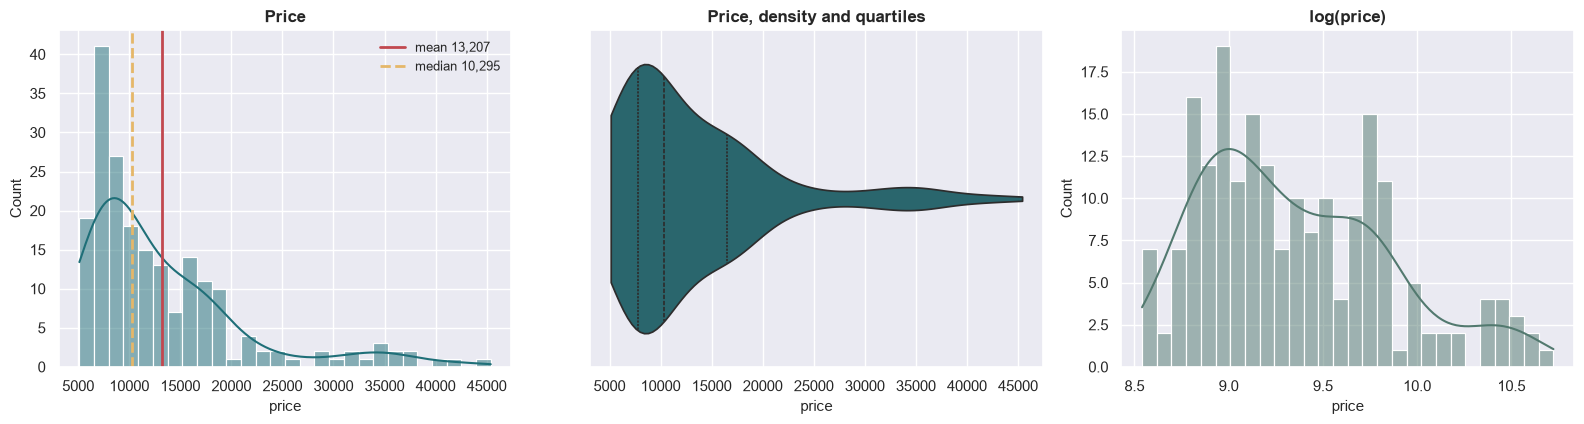

skew price      : 1.810
skew log(price) : 0.679
mean / median   : 1.283
IQR             : 7,775 to 16,500


In [21]:
price = cars["price"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

sns.histplot(price, bins=28, kde=True, ax=axes[0], color=TEAL)
axes[0].axvline(price.mean(), color=CORAL, lw=2, label=f"mean {price.mean():,.0f}")
axes[0].axvline(price.median(), color=SAND, lw=2, ls="--",
                label=f"median {price.median():,.0f}")
axes[0].set_title("Price")
axes[0].legend(fontsize=9)

sns.violinplot(x=price, ax=axes[1], color=TEAL, cut=0, inner="quartile")
axes[1].set_title("Price, density and quartiles")

sns.histplot(np.log(price), bins=28, kde=True, ax=axes[2], color="#52796f")
axes[2].set_title("log(price)")

plt.tight_layout()
chart("chart_02_price_distribution")

print(f"skew price      : {price.skew():.3f}")
print(f"skew log(price) : {np.log(price).skew():.3f}")
print(f"mean / median   : {price.mean() / price.median():.3f}")
print(f"IQR             : {price.quantile(0.25):,.0f} to {price.quantile(0.75):,.0f}")

**Price is strongly right-skewed.**

- Skew **1.810**, falling to **0.679** under a log transform.
- The mean is **1.283×** the median — the long upper tail dragging the average away
  from the typical car.
- The middle half of the market lies between **7,775 and 16,500**, while the full
  range runs to 45,400.

The violin in the centre panel shows the shape the summary statistics describe: a
dense body at the low end and a thin tail stretching far to the right, with the
quartile lines bunched in the lower third.

The practical consequence, which recurs in 4a and in the recommendation, is that
**price behaves multiplicatively.** Features add a percentage to a car's value, not a
fixed sum.

### 2.4 How the other numeric variables are distributed

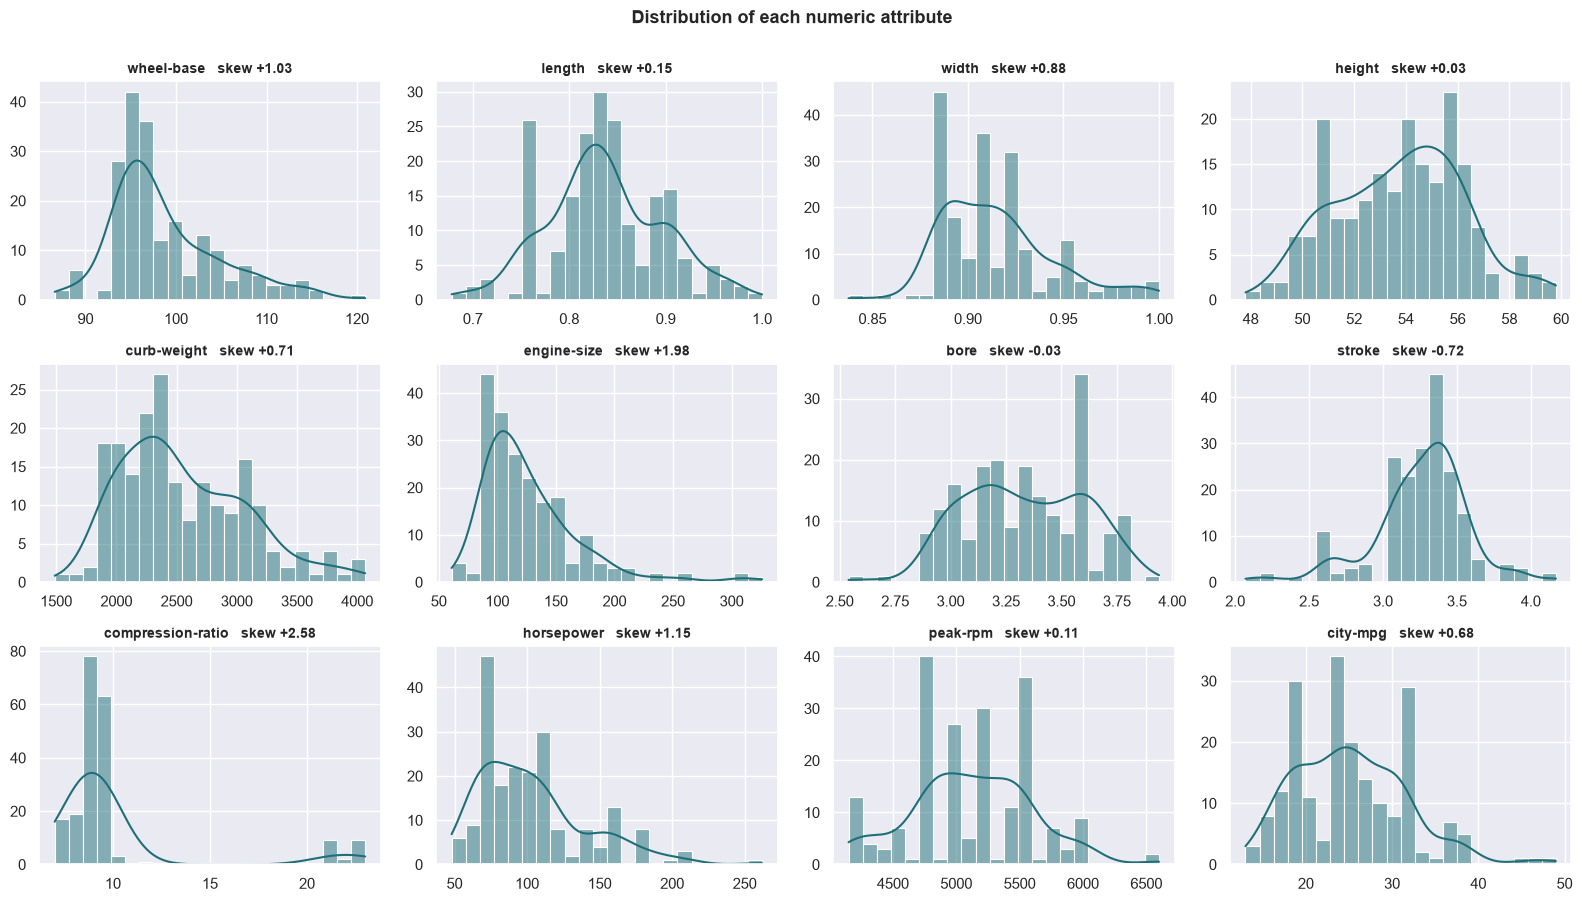

In [22]:
panel = [c for c in NUMERIC if c != "normalized-losses"][:12]

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, column in zip(axes.flat, panel):
    sns.histplot(cars[column], bins=22, kde=True, ax=ax, color=TEAL,
                 line_kws={"lw": 1.5, "color": CORAL})
    ax.set_title(f"{column}   skew {cars[column].skew():+.2f}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Distribution of each numeric attribute", y=1.00, fontsize=13,
             fontweight="bold")
plt.tight_layout()
chart("chart_03_numeric_distributions")

**Distribution of each numeric attribute with its skew.** Three shapes recur.

`wheel-base`, `curb-weight`, `engine-size` and `horsepower` are right-skewed in the
same direction as price — the first visual evidence that they track it.
`compression-ratio` shows the two separated spikes of the diesel/petrol mixture.
`bore`, `height` and `peak-rpm` are near-symmetric and turn out to be near-useless
for price.

`stroke` is the one left-skewed variable (-0.72), with a cluster of low values from
the small-displacement economy cars.

### 2.5 How the categorical variables are distributed

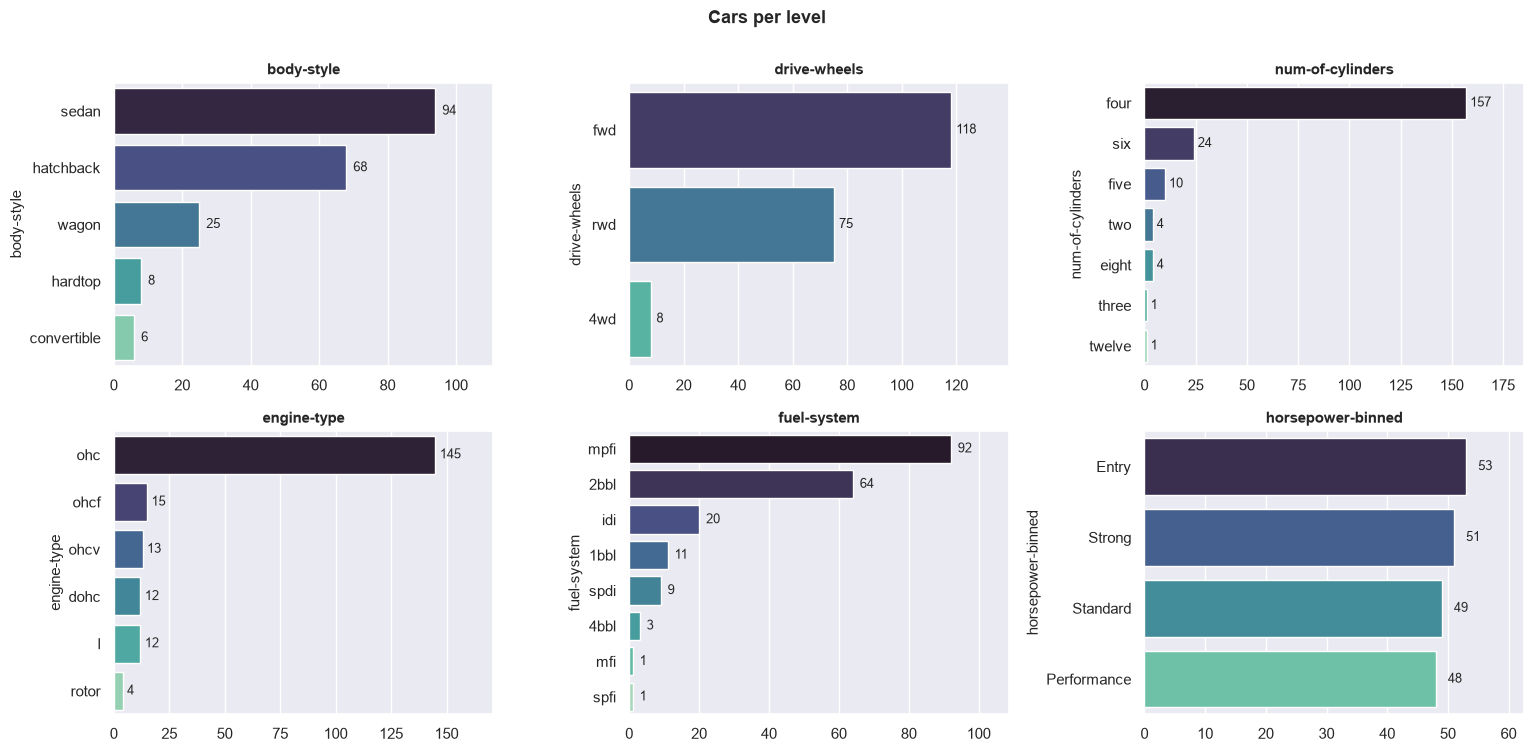

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15.5, 7.5))
for ax, column in zip(axes.flat, ["body-style", "drive-wheels", "num-of-cylinders",
                                  "engine-type", "fuel-system", "horsepower-binned"]):
    counts = cars[column].value_counts()
    sns.barplot(x=counts.to_numpy(), y=counts.index.astype(str), ax=ax,
                hue=counts.index.astype(str), palette="mako", legend=False)
    for i, value in enumerate(counts.to_numpy()):
        ax.text(value + 2, i, f"{value}", va="center", fontsize=9)
    ax.set_xlim(0, counts.max() * 1.18)
    ax.set_title(column, fontsize=11)
fig.suptitle("Cars per level", y=1.00, fontsize=13, fontweight="bold")
plt.tight_layout()
chart("chart_04_categorical_counts")

**Cars per level for the six most analytically useful categorical variables.**

`horsepower-binned` is now visibly the best-balanced of them, with four bands of
roughly fifty cars each — a direct result of the quantile rebuild in stage `derive`.
Every other panel shows a dominant level and a long tail of sparse ones: 145 `ohc`
engines against 4 rotary, 92 `mpfi` fuel systems against single-figure counts for
three others.

Those sparse levels are where the misleading group means in section 3 come from.

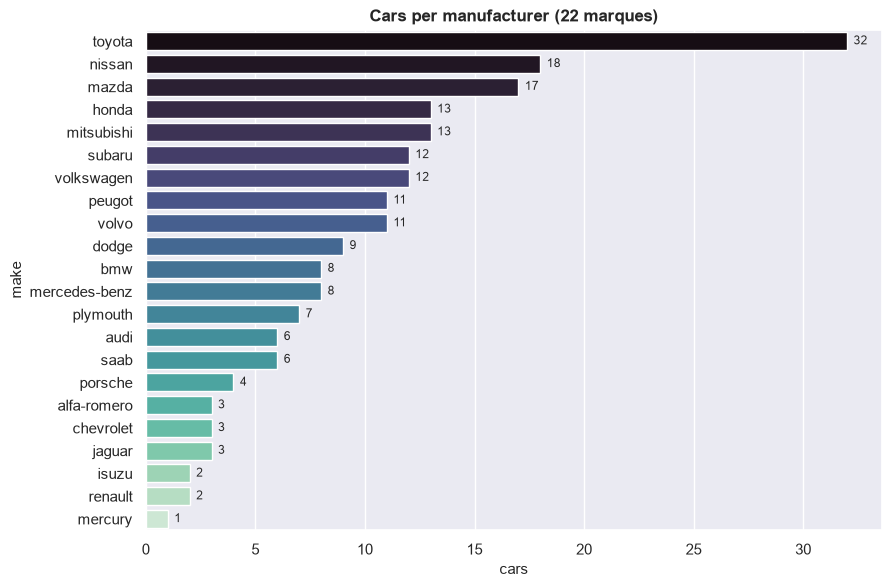

In [24]:
plt.figure(figsize=(9.5, 6.5))
makes = cars["make"].value_counts()
sns.barplot(x=makes.to_numpy(), y=makes.index, hue=makes.index, palette="mako",
            legend=False)
for i, value in enumerate(makes.to_numpy()):
    plt.text(value + 0.3, i, str(value), va="center", fontsize=8.5)
plt.title(f"Cars per manufacturer ({makes.size} marques)")
plt.xlabel("cars")
chart("chart_05_make_counts")

**Cars per manufacturer.** Toyota (32), Nissan (18) and Mazda (17) together supply a
third of the dataset; seven marques have fewer than five cars.

This chart is the justification for excluding `make` from the model in 5.1. It
records the largest effect size of any variable in section 3.6 *and* has the most
thinly sampled levels — a combination that fits the sample well and generalises
badly.

### 2.6 Correlation structure

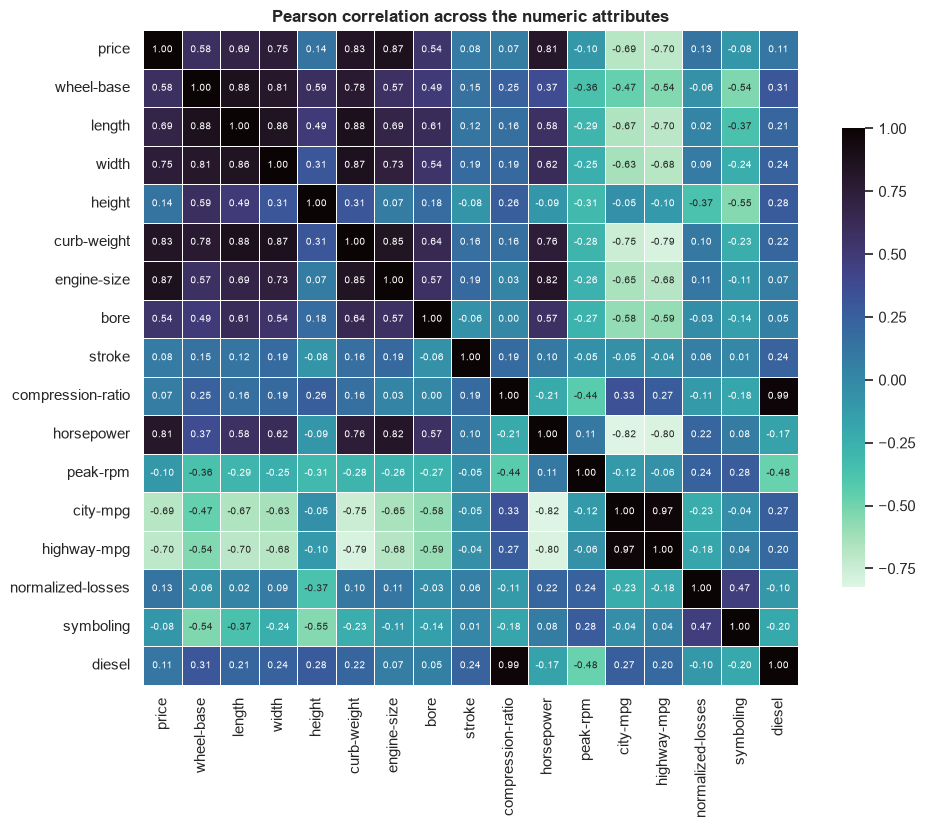

In [25]:
corr_columns = ["price"] + [c for c in NUMERIC] + ["symboling", "diesel"]
matrix = cars[corr_columns].corr()

plt.figure(figsize=(11.5, 8.5))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="mako_r", square=True,
            linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.7},
            annot_kws={"size": 7.5})
plt.title("Pearson correlation across the numeric attributes")
chart("chart_06_correlation_heatmap")

**Pearson correlation across all numeric attributes.** The dominant structure is the
dark block in the upper left: `engine-size`, `curb-weight`, `horsepower`, `width`,
`length` and `wheel-base` all correlate strongly with price **and with one another**.

That block is a single underlying property — how big the car is — measured six
different ways. It is the reason the variance inflation check in 5.5 is necessary
before any individual coefficient can be interpreted.

The fuel-economy variables form the mirror image: `city-mpg` and `highway-mpg`
correlate negatively with price and with everything in that block, because heavier and
more powerful cars use more fuel. That is the same effect with its sign reversed, not
an independent one.

In [26]:
(matrix["price"].drop("price").sort_values(key=abs, ascending=False)
    .to_frame("r")
    .assign(**{"r squared": lambda d: (d["r"] ** 2).round(3),
               "strength": lambda d: pd.cut(
                   d["r"].abs(), bins=[0, 0.3, 0.5, 0.7, 1.0],
                   labels=["negligible", "moderate", "strong", "very strong"])})
    .round(3))

,r,r squared,strength
engine-size,0.87,0.76,very strong
curb-weight,0.83,0.70,very strong
horsepower,0.81,0.66,very strong
width,0.75,0.56,very strong
highway-mpg,-0.70,0.50,very strong
length,0.69,0.48,strong
city-mpg,-0.69,0.47,strong
wheel-base,0.58,0.34,strong
bore,0.54,0.29,strong
height,0.14,0.02,negligible


**Every numeric variable ranked by correlation with price, binned into strength
bands — and the bands reveal an unusually clean separation.**

Five variables are "very strong" (|r| ≥ 0.7): `engine-size` 0.87, `curb-weight` 0.83,
`horsepower` 0.81, `width` 0.75, `highway-mpg` -0.70. Four more are "strong".
Then **seven variables drop straight to "negligible"**, with nothing in the moderate
band at all.

The gap is abrupt: `bore` explains 29% of price variance and the next variable,
`height`, explains 2%. There is no gradual decline — the dataset splits cleanly into
nine variables that matter and seven that do not. That is what makes the feature
selection in section 5 a well-posed problem rather than a judgement call about where
to draw a line.

`symboling` at -0.08 is worth noting as a substantive result: the insurance risk
rating is essentially uncorrelated with price, so insurers and buyers are valuing
different properties of a car.

### 2.7 Patterns observed

Six patterns emerge from the descriptive work, each with a consequence for the
sections that follow.

**1. Price is right-skewed and multiplicative.** Skew 1.810, falling to 0.679 in logs;
mean 1.283× median; middle half of the market between 7,775 and 16,500. *Consequence:
pricing rules are expressed as percentages, not fixed increments.*

**2. There is a clean break between signal and noise.** Nine variables correlate with
price at |r| ≥ 0.54 and seven at |r| ≤ 0.14, with nothing in between. *Consequence:
feature selection in section 5 is a well-posed problem rather than an arbitrary
cut-off.*

**3. Six variables measure one underlying thing.** `engine-size`, `curb-weight`,
`horsepower`, `width`, `length` and `wheel-base` correlate 0.7–0.9 with each other.
*Consequence: variance inflation is checked in 5.5 before any coefficient is read.*

**4. The cars differ far more in power than in shape.** Coefficient of variation 0.33
–0.39 for engine size, horsepower and compression ratio against 0.03–0.05 for width
and height. *Consequence: the dimension variables are weak predictors, and `height`
duly manages r = 0.14.*

**5. Every categorical variable except `horsepower-binned` is badly unbalanced.** 98.5%
front-engined, 78% four-cylinder, 72% `ohc`, seven marques with fewer than five cars.
*Consequence: all group statistics carry their n, and section 3.5 filters the ranking
to adequately-sampled variables.*

**6. Two columns are structurally compromised.** `compression-ratio` is a mixture of
two engine populations, not one distribution, and `normalized-losses` repeats its
modal value on a fifth of all rows. *Consequence: neither is read at face value, and
the `diesel` indicator is kept so models can condition on the mixture.*

---
# 3. Grouping and average price &nbsp;·&nbsp; *[5 Marks]*

### 3.1 Average price by drive-wheels

In [27]:
drive = price_summary(cars, "drive-wheels")
drive.round(0)

,n,mean,ci_low,ci_high,median,sd
level,,,,,,
fwd,118,"9,245.00","8,649.00","9,851.00","8,192.00","3,346.00"
4wd,8,"10,241.00","8,525.00","12,625.00","9,006.00","3,288.00"
rwd,75,"19,758.00","17,707.00","21,862.00","16,900.00","9,083.00"


**Rear-wheel-drive cars average 19,758 against 9,245 for front-wheel drive** — a gap
of 10,513, slightly more than double.

The bootstrap intervals settle whether these are three distinct groups or two:

- **fwd** [8,649, 9,851] — narrow, on 118 cars.
- **4wd** [8,525, 12,625] — nearly four times wider, on 8 cars, and **overlapping fwd
  substantially**.
- **rwd** [17,707, 21,862] — entirely clear of both.

The defensible conclusion is **two groups, not three**. Note also that rwd's standard
deviation (9,083) is nearly three times fwd's (3,346) and its median (16,900) sits
far below its mean — this is a broad, heterogeneous category covering cheap sports
cars and the entire luxury segment, not a price band.

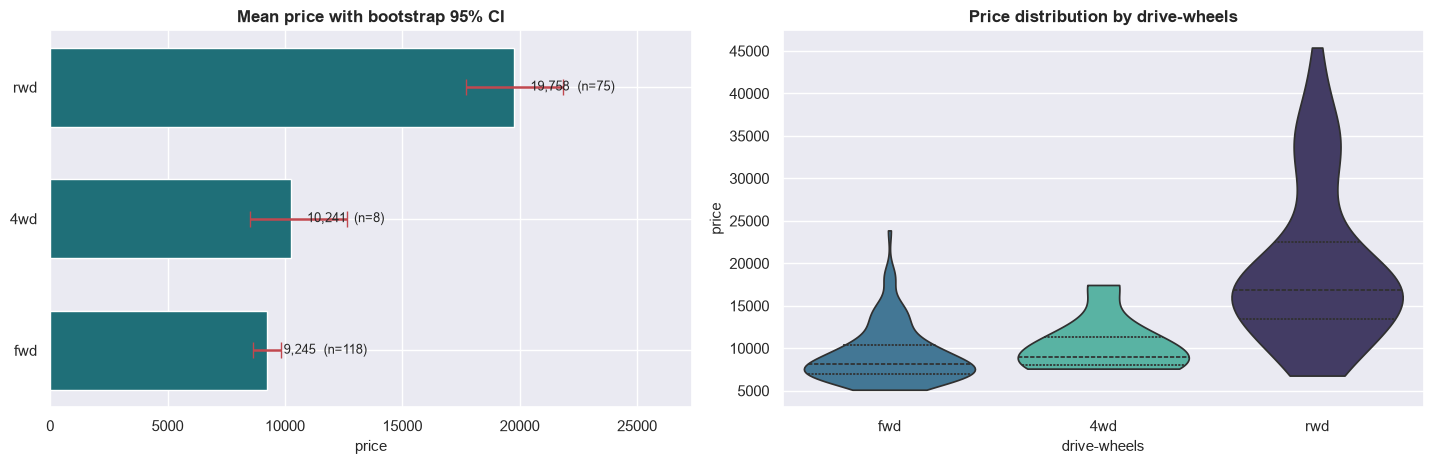

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))

axes[0].barh(drive.index, drive["mean"], color=TEAL, height=0.6,
             xerr=[drive["mean"] - drive["ci_low"], drive["ci_high"] - drive["mean"]],
             error_kw={"ecolor": CORAL, "capsize": 6, "lw": 1.8})
for i, (mean, n) in enumerate(zip(drive["mean"], drive["n"])):
    axes[0].text(mean + 700, i, f"{mean:,.0f}  (n={n})", va="center", fontsize=9)
axes[0].set_xlim(0, drive["ci_high"].max() * 1.25)
axes[0].set_title("Mean price with bootstrap 95% CI")
axes[0].set_xlabel("price")

sns.violinplot(data=cars, x="drive-wheels", y="price", order=drive.index,
               ax=axes[1], hue="drive-wheels", palette="mako", legend=False,
               cut=0, inner="quartile")
axes[1].set_title("Price distribution by drive-wheels")

plt.tight_layout()
chart("chart_07_price_by_drive_wheels")

**Left: the means with their uncertainty. Right: the distributions that produced
them.**

The violin explains the width of the 4wd interval — eight points cannot define a
distribution. It also shows that the rwd violin is broad and flat rather than
concentrated, so its mean of 19,758 describes very few actual cars.

Presenting both panels together is the point: the bar chart alone would invite a
reader to treat 4wd's 10,241 as comparable in reliability to fwd's 9,245.

### 3.2 Average price by body-style

In [29]:
body = price_summary(cars, "body-style")
body.round(0)

,n,mean,ci_low,ci_high,median,sd
level,,,,,,
hatchback,68,"9,957.00","9,004.00","10,991.00","8,672.00","4,149.00"
wagon,25,"12,372.00","10,541.00","14,447.00","11,694.00","5,121.00"
sedan,94,"14,460.00","12,744.00","16,308.00","11,078.00","8,523.00"
convertible,6,"21,890.00","14,242.00","29,723.00","17,084.00","11,188.00"
hardtop,8,"22,208.00","13,263.00","31,854.00","19,688.00","14,556.00"


**Body style spans hatchback at 9,957 to hardtop at 22,208, but the confidence
intervals undermine most of that ranking.**

Convertible [14,242, 29,723] on 6 cars and hardtop [13,263, 31,854] on 8 are both
enormous, and both overlap the sedan interval [12,744, 16,308] comfortably. Only
`hatchback` [9,004, 10,991] is cleanly separated from the rest.

The standard deviations say the same thing from another angle: sedans vary by 8,523
around a mean of 14,460, because "sedan" covers a 5,499 Chevrolet and a 41,315 BMW.
**Body style describes a shape, and shape is only loosely connected to price.**

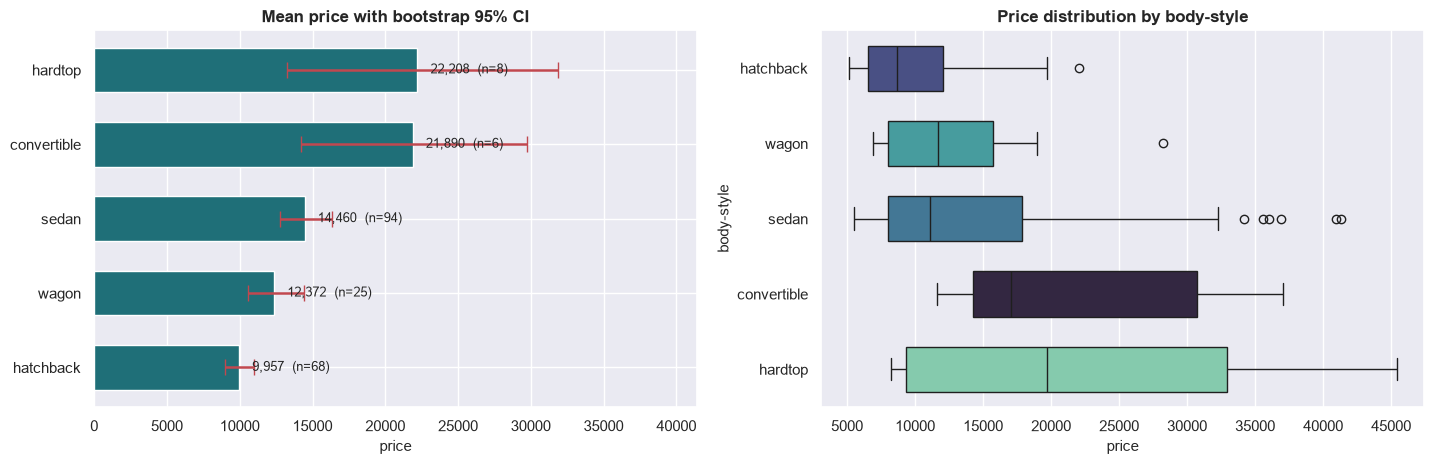

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))

axes[0].barh(body.index, body["mean"], color=TEAL, height=0.6,
             xerr=[body["mean"] - body["ci_low"], body["ci_high"] - body["mean"]],
             error_kw={"ecolor": CORAL, "capsize": 6, "lw": 1.8})
for i, (mean, n) in enumerate(zip(body["mean"], body["n"])):
    axes[0].text(mean + 900, i, f"{mean:,.0f}  (n={n})", va="center", fontsize=9)
axes[0].set_xlim(0, body["ci_high"].max() * 1.3)
axes[0].set_title("Mean price with bootstrap 95% CI")
axes[0].set_xlabel("price")

sns.boxplot(data=cars, y="body-style", x="price", order=body.index, ax=axes[1],
            hue="body-style", palette="mako", legend=False, width=0.6)
axes[1].set_title("Price distribution by body-style")

plt.tight_layout()
chart("chart_08_price_by_body_style")

**The intervals plotted at scale, beside the distributions.** The contrast between
the tight hatchback, wagon and sedan intervals and the enormous convertible and
hardtop intervals is the finding.

A reader shown only five means would rank body styles confidently. Shown the
intervals, the honest conclusion is that this dataset supports exactly one
body-style claim: hatchbacks are cheaper than everything else.

### 3.3 Two grouping variables together

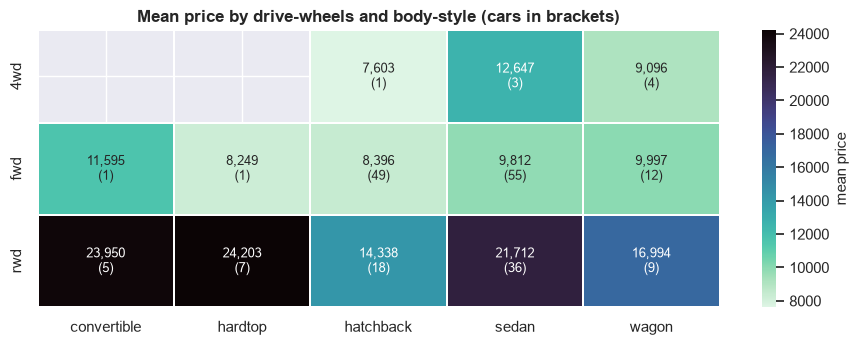

In [31]:
means = cars.pivot_table(index="drive-wheels", columns="body-style",
                         values="price", aggfunc="mean")
counts = cars.pivot_table(index="drive-wheels", columns="body-style",
                          values="price", aggfunc="count")

labels = means.copy().astype("object")
for row in means.index:
    for col in means.columns:
        value = means.loc[row, col]
        labels.loc[row, col] = ("n/a" if pd.isna(value)
                                else f"{value:,.0f}\n({int(counts.loc[row, col])})")

plt.figure(figsize=(11, 3.6))
sns.heatmap(means, annot=labels, fmt="", cmap="mako_r", linewidths=1.4,
            linecolor="white", cbar_kws={"label": "mean price"},
            annot_kws={"size": 9.5})
plt.title("Mean price by drive-wheels and body-style (cars in brackets)")
plt.xlabel("")
plt.ylabel("")
chart("chart_09_two_way_grid")

**Price by drive-wheels and body-style jointly, with cars per cell in brackets.**

Reading across each row, the rwd cell is darker than the fwd cell in **every** body
style the two share — rwd sedans average 21,712 against fwd sedans at 9,812, rwd
hatchbacks 14,338 against fwd hatchbacks 8,396, and the same ordering holds for
convertibles, hardtops and wagons.

That consistency establishes that the two variables are not restating each other:
drive configuration moves price *within* body style. Cells marked `n/a` are
combinations that do not occur, and several populated cells rest on one to three
cars, which is why the count is printed in every tile.

### 3.4 Average price across the remaining groupings

In [32]:
blocks = []
for column in ["num-of-cylinders", "engine-type", "aspiration", "engine-location",
               "num-of-doors", "fuel-system", "horsepower-binned", "symboling"]:
    table = (cars.groupby(column, observed=True)["price"]
                 .agg(n="count", mean="mean", median="median", sd="std")
                 .sort_values("mean").round(0))
    print(f"--- {column} ---")
    print(table.to_string())
    print()
    blocks.append(table.assign(variable=column))

--- num-of-cylinders ---
                    n      mean    median       sd
num-of-cylinders                                  
three               1  5,151.00  5,151.00      NaN
four              157 10,303.00  8,949.00 3,944.00
two                 4 13,020.00 12,745.00 2,079.00
five               10 22,008.00 21,398.00 6,284.00
six                24 23,672.00 21,038.00 8,850.00
twelve              1 36,000.00 36,000.00      NaN
eight               4 38,900.00 38,008.00 5,276.00

--- engine-type ---
               n      mean    median        sd
engine-type                                   
ohc          145 11,567.00  9,095.00  6,445.00
rotor          4 13,020.00 12,745.00  2,079.00
ohcf          15 13,739.00  9,233.00 10,930.00
l             12 14,628.00 16,105.00  3,674.00
dohc          12 18,116.00 16,249.00  7,964.00
ohcv          13 25,098.00 19,699.00 11,443.00

--- aspiration ---
              n      mean    median       sd
aspiration                                  
std      

**Price summaries for the eight remaining groupings.**

`num-of-cylinders` has the widest span — 5,151 to 38,900 — but those extremes are one
car and four cars. The trustworthy comparison inside this variable is four-cylinder
(157 cars, 10,303) against six-cylinder (24 cars, 23,672), a 2.3× difference.

`engine-location` shows front 12,884 against rear 34,528, which looks decisive until
the n of 3 is read: all three rear-engined cars are Porsches, so this statistic
measures a brand, not a design.

`aspiration` is instructive. The means differ by 30% (12,542 vs 16,255) but the
**medians differ by 64%** (9,538 vs 15,686). The naturally aspirated group contains
most of the cheap cars *and* most of the luxury ones, so its mean is pulled up while
its median stays low — a case where the mean actively understates the difference.

`engine-type` ranks `ohcf` third by mean, but with a standard deviation of 10,930
around a mean of 13,739 — larger than the mean itself — it is not a coherent group.

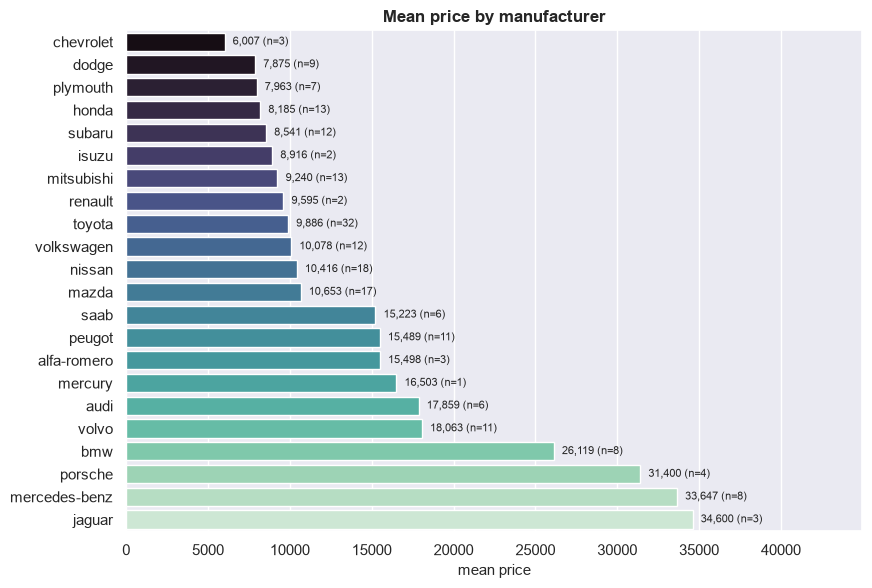

In [33]:
plt.figure(figsize=(9.5, 6.5))
by_make = cars.groupby("make")["price"].agg(["count", "mean"]).sort_values("mean")
sns.barplot(x=by_make["mean"], y=by_make.index, hue=by_make.index, palette="mako",
            legend=False)
for i, (mean, n) in enumerate(zip(by_make["mean"], by_make["count"])):
    plt.text(mean + 500, i, f"{mean:,.0f} (n={n})", va="center", fontsize=8)
plt.xlim(0, by_make["mean"].max() * 1.3)
plt.title("Mean price by manufacturer")
plt.xlabel("mean price")
plt.ylabel("")
chart("chart_10_price_by_make")

**Mean price by manufacturer, from Chevrolet at 6,007 to Jaguar at 34,600** — a 5.8×
range, the second-widest of any variable in the dataset.

Every marque above 25,000 rests on eight cars or fewer. The variable with the largest
apparent effect is the one whose levels are most thinly measured, which is the
central tension `make` presents throughout this notebook.

### 3.5 Highest and lowest priced groups

In [34]:
extremes = []
for column in NOMINAL + ["symboling"]:
    grouped = cars.groupby(column, observed=True)["price"].agg(["count", "mean"])
    low, high = grouped["mean"].idxmin(), grouped["mean"].idxmax()
    extremes.append({
        "variable": column,
        "cheapest": f"{low} ({grouped.loc[low, 'mean']:,.0f})",
        "n cheapest": int(grouped.loc[low, "count"]),
        "dearest": f"{high} ({grouped.loc[high, 'mean']:,.0f})",
        "n dearest": int(grouped.loc[high, "count"]),
        "ratio": round(grouped["mean"].max() / grouped["mean"].min(), 2),
        "min group size": int(grouped["count"].min()),
    })

extreme_table = (pd.DataFrame(extremes).sort_values("ratio", ascending=False)
                   .reset_index(drop=True))
extreme_table

,variable,cheapest,n cheapest,dearest,n dearest,ratio,min group size
0,num-of-cylinders,"three (5,151)",1,"eight (38,900)",4,7.55,1
1,make,"chevrolet (6,007)",3,"jaguar (34,600)",3,5.76,1
2,horsepower-binned,"Entry (7,160)",53,"Performance (23,463)",48,3.28,48
3,engine-location,"front (12,884)",198,"rear (34,528)",3,2.68,3
4,fuel-system,"2bbl (7,433)",64,"mpfi (17,605)",92,2.37,1
5,body-style,"hatchback (9,957)",68,"hardtop (22,208)",8,2.23,6
6,engine-type,"ohc (11,567)",145,"ohcv (25,098)",13,2.17,4
7,drive-wheels,"fwd (9,245)",118,"rwd (19,758)",75,2.14,8
8,symboling,"1 (9,649)",52,"-1 (17,331)",22,1.80,3
9,aspiration,"std (12,542)",165,"turbo (16,255)",36,1.30,36


**Highest and lowest priced group for every categorical variable** — the brief's
question answered directly, with the sample sizes that determine whether each answer
means anything.

The `min group size` column is the one that separates findings from artefacts:

- **`num-of-cylinders` ×7.55** — one three-cylinder car against four eight-cylinder
  cars. The direction is certain; the magnitude is not.
- **`make` ×5.76** — three Chevrolets against three Jaguars.
- **`horsepower-binned` ×3.28** — Entry (53 cars) against Performance (48 cars), with
  **no level in the variable below 48**. This is by a wide margin the most reliable
  large ratio in the table, and it is a direct payoff from the quantile rebuild.
- **`engine-location` ×2.68** — three cars, all Porsches.
- **`drive-wheels` ×2.14** — 118 against 75, the other solidly-sampled comparison.
- **`num-of-doors` ×1.05** — no meaningful difference, and 3.6 confirms it is the only
  variable that fails significance.

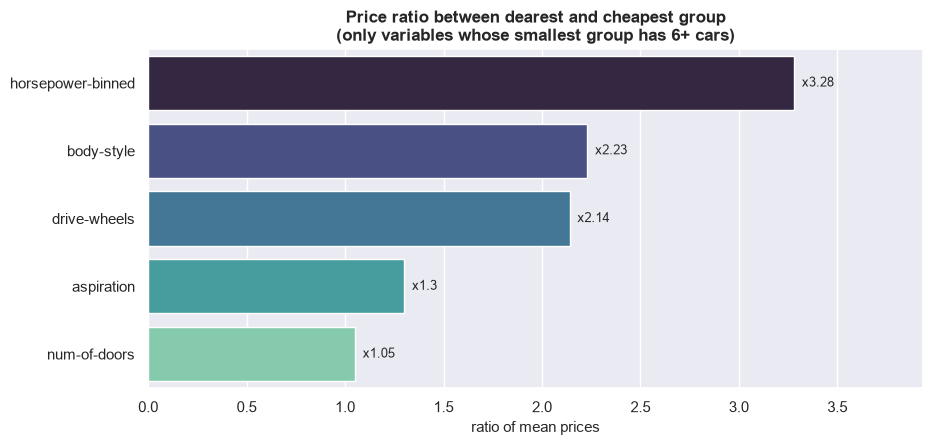

In [35]:
# Only the comparisons where both extreme groups are adequately sampled.
reliable = extreme_table[extreme_table["min group size"] >= 6]

plt.figure(figsize=(10, 4.4))
sns.barplot(data=reliable, x="ratio", y="variable", hue="variable", palette="mako",
            legend=False)
for i, row in enumerate(reliable.itertuples()):
    plt.text(row.ratio + 0.04, i, f"x{row.ratio}", va="center", fontsize=9.5)
plt.xlim(0, reliable["ratio"].max() * 1.2)
plt.title("Price ratio between dearest and cheapest group\n"
          "(only variables whose smallest group has 6+ cars)")
plt.xlabel("ratio of mean prices")
plt.ylabel("")
chart("chart_11_reliable_price_ratios")

**The same ratios, filtered to variables whose smallest group holds at least six
cars.** Five of the eleven survive.

Everything with a dramatic ratio in the previous table — cylinder count, make, engine
location, fuel system — is excluded, because each depends on a group of one to four
cars. What remains is the honest version of the answer: **horsepower band (×3.28) and
drive configuration (×2.14) are the two categorical variables that genuinely separate
price**, body style is a weak third, and aspiration and door count are marginal.

### 3.6 Testing the group differences: ANOVA with omega squared

In [36]:
# eta squared is biased upward in small samples because it uses the sample's own
# group means. omega squared corrects for that bias and is reported alongside.
results = []
for column in NOMINAL + ["symboling"]:
    groups = [block["price"].to_numpy()
              for _, block in cars.groupby(column, observed=True) if len(block) > 1]
    f_stat, p_value = stats.f_oneway(*groups)

    k = len(groups)
    n = sum(len(g) for g in groups)
    grand = price.mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = ((price - grand) ** 2).sum()
    ss_within = ss_total - ss_between
    ms_within = ss_within / (n - k)

    eta_sq = ss_between / ss_total
    omega_sq = (ss_between - (k - 1) * ms_within) / (ss_total + ms_within)

    results.append({"variable": column, "levels": k, "F": round(f_stat, 2),
                    "p": p_value, "eta squared": round(eta_sq, 3),
                    "omega squared": round(omega_sq, 3),
                    "bias": round(eta_sq - omega_sq, 3),
                    "significant": p_value < 0.05})

anova = (pd.DataFrame(results).sort_values("omega squared", ascending=False)
           .reset_index(drop=True))
anova.assign(p=lambda d: d["p"].map("{:.2e}".format))

,variable,levels,F,p,eta squared,omega squared,bias,significant
0,make,21,34.86,4.04e-51,0.80,0.77,0.02,True
1,horsepower-binned,4,95.05,4.47e-38,0.59,0.58,0.01,True
2,num-of-cylinders,5,76.35,8.89e-39,0.58,0.57,0.01,True
3,drive-wheels,3,67.95,3.39e-23,0.41,0.40,0.01,True
4,fuel-system,6,21.01,9.56e-17,0.35,0.33,0.02,True
5,engine-type,6,9.85,2.09e-08,0.20,0.18,0.02,True
6,body-style,5,9.13,8.78e-07,0.16,0.14,0.02,True
7,symboling,6,6.85,6.56e-06,0.15,0.13,0.02,True
8,engine-location,2,24.50,1.58e-06,0.11,0.10,0.01,True
9,aspiration,2,6.63,1.07e-02,0.03,0.03,0.01,True


**ANOVA with both the biased and the bias-corrected effect size.**

Eta squared uses the sample's own group means, so it is inflated in small samples —
it reports some variance explained even when the true effect is zero. Omega squared
subtracts that expected inflation. Reporting both makes the size of the bias visible
rather than leaving it implicit.

**Ten of eleven variables are significant.** `num-of-doors` is the exception
(F = 0.36, p = 0.550) and its omega squared is **-0.00** — a *negative* corrected
effect size, which is omega squared's way of reporting that the observed group
difference is smaller than chance alone would produce. Two-door and four-door cars
cost the same.

The bias column is reassuringly small throughout (0.01–0.02), so the rankings are
stable under either measure: `make` 0.77, `horsepower-binned` 0.58,
`num-of-cylinders` 0.57, `drive-wheels` 0.40.

Two details in the `levels` column need explanation. It reads 21 for `make` and 5 for
`num-of-cylinders`, not 22 and 7, because the loop excludes any group with a single
car — an ANOVA cannot use a group with no within-group variance. Mercury, and the
three- and twelve-cylinder cars, are therefore absent from these tests.

The usual caveat applies to the ranking: **effect size grows with the number of
levels**, so `make` at 21 levels and `aspiration` at 2 are not directly comparable.
On a like-for-like basis `horsepower-binned` (0.58 from 4 levels) and `drive-wheels`
(0.40 from 3) are the most efficient categorical predictors here.

---
# 4. Effect of the independent attributes on price &nbsp;·&nbsp; *[5 Marks]*

## 4a. Continuous variables against price &nbsp;·&nbsp; *[2 Marks]*

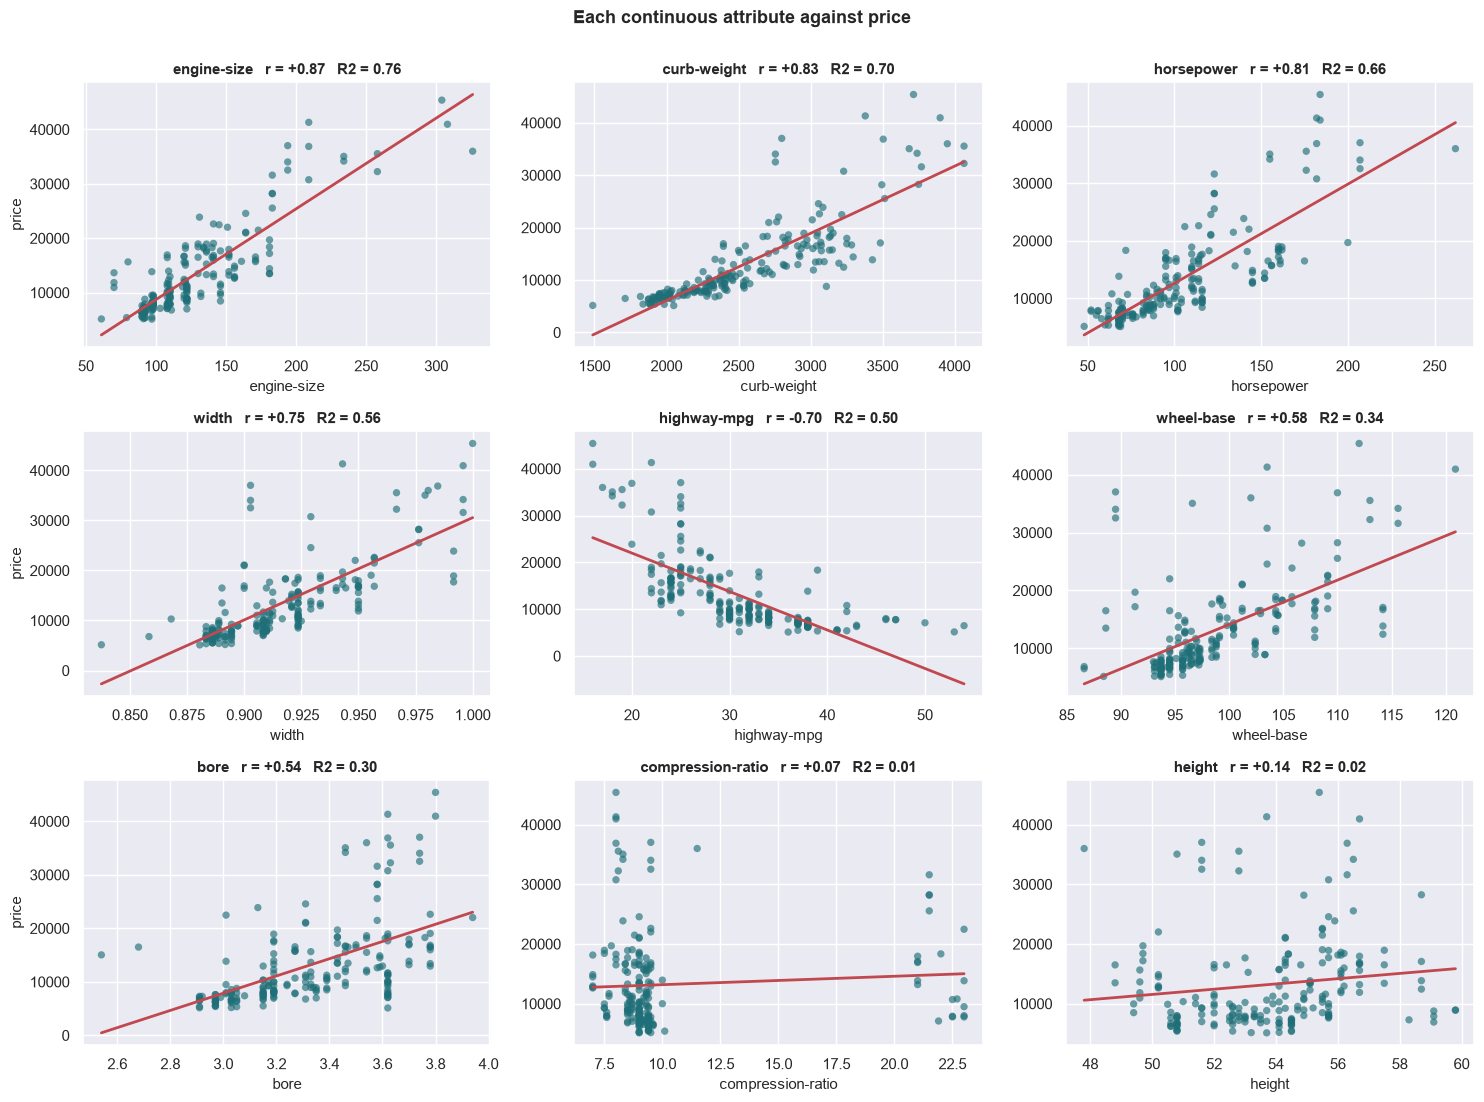

In [37]:
scatter_columns = ["engine-size", "curb-weight", "horsepower", "width",
                   "highway-mpg", "wheel-base", "bore", "compression-ratio", "height"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, column in zip(axes.flat, scatter_columns):
    sns.scatterplot(data=cars, x=column, y="price", ax=ax, color=TEAL, s=28,
                    alpha=0.65, edgecolor="none")
    slope, intercept = np.polyfit(cars[column], price, 1)
    grid = np.linspace(cars[column].min(), cars[column].max(), 100)
    ax.plot(grid, slope * grid + intercept, color=CORAL, lw=2)
    r, p = stats.pearsonr(cars[column], price)
    ax.set_title(f"{column}   r = {r:+.2f}   R2 = {r**2:.2f}", fontsize=10.5)
    ax.set_ylabel("price" if ax in axes[:, 0] else "")
fig.suptitle("Each continuous attribute against price", y=1.00, fontsize=13,
             fontweight="bold")
plt.tight_layout()
chart("chart_12_continuous_vs_price")

**Each continuous attribute against price with a fitted line.** Six of the nine show
a strong relationship.

The three strongest — `engine-size` (R² 0.76), `curb-weight` (0.70) and `horsepower`
(0.66) — share a visible characteristic: **the points fan outward as the line rises.**
Variance in price grows with the predictor, so a single straight line understates the
error badly at the top of the range and overstates it at the bottom.

`compression-ratio` (r = +0.07) shows the two vertical stacks of the diesel/petrol
mixture with an empty gap between them; its fitted line passes through a region where
no cars exist, and the correlation is not interpretable. `height` (r = +0.14) is a
formless cloud.

In [38]:
rows = []
for column in NUMERIC + ["symboling", "diesel"]:
    r, p_r = stats.pearsonr(cars[column], price)
    rho, p_rho = stats.spearmanr(cars[column], price)
    rows.append({"variable": column, "pearson r": round(r, 3),
                 "spearman rho": round(rho, 3), "R squared": round(r ** 2, 3),
                 "p": p_r, "significant": p_r < 0.05,
                 "curved": abs(rho) - abs(r) > 0.05})

effects = (pd.DataFrame(rows).sort_values("R squared", ascending=False)
             .reset_index(drop=True))
effects.assign(p=lambda d: d["p"].map("{:.2e}".format))

,variable,pearson r,spearman rho,R squared,p,significant,curved
0,engine-size,0.87,0.83,0.76,9.27e-64,True,False
1,curb-weight,0.83,0.91,0.70,2.19e-53,True,True
2,horsepower,0.81,0.85,0.66,6.27e-48,True,False
3,width,0.75,0.81,0.56,9.20e-38,True,True
4,highway-mpg,-0.70,-0.83,0.50,1.75e-31,True,True
5,length,0.69,0.81,0.48,8.02e-30,True,True
6,city-mpg,-0.69,-0.83,0.47,2.32e-29,True,True
7,wheel-base,0.58,0.68,0.34,8.08e-20,True,True
8,bore,0.54,0.65,0.29,8.05e-17,True,True
9,height,0.14,0.26,0.02,5.51e-02,False,True


**Pearson and Spearman side by side, with a `curved` flag where the rank correlation
exceeds the linear one by more than 0.05.**

**Eight variables are flagged as curved**, including five of the top eight.
`curb-weight` goes from 0.83 to **0.91**, `highway-mpg` from -0.70 to **-0.83**,
`length` from 0.69 to 0.81. In each case the linear coefficient *understates* the
true strength of the relationship.

This has a direct consequence for section 5: a linear model is being fitted to
relationships that are reliably curved, so its R² is a floor rather than a ceiling —
and it predicts in advance that the gradient-boosted trees in 5.3, which can fit
curvature, will outperform it. They do, substantially.

`compression-ratio` is the one variable whose Spearman (-0.18) has the **opposite
sign** to its Pearson (+0.07). Neither is meaningful; the variable is a mixture of two
populations and no single correlation summarises it.

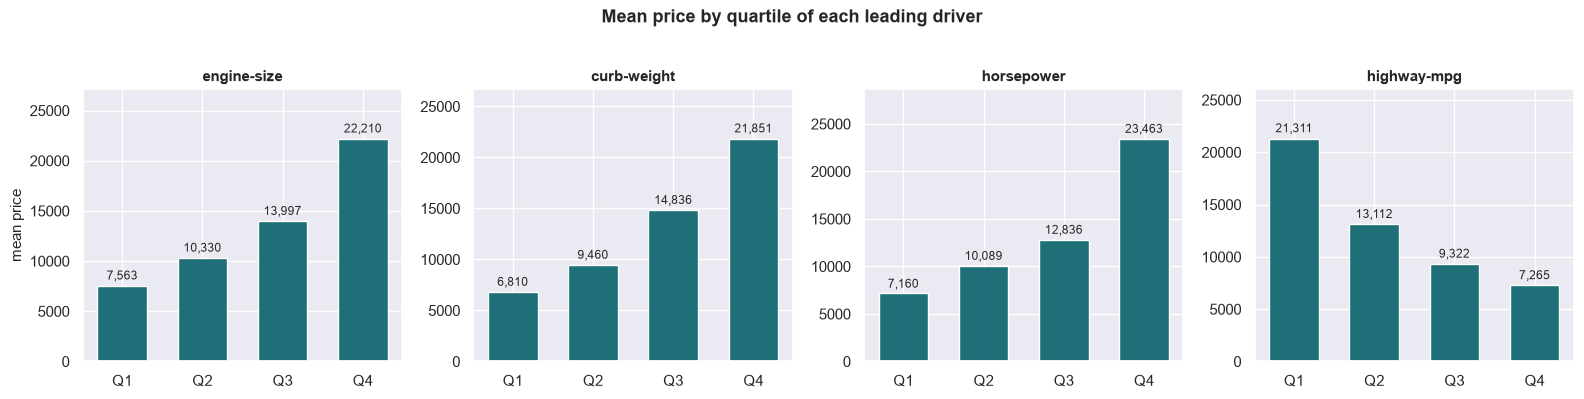

In [39]:
# Does the price per unit stay constant as the variable grows? Split each driver
# into quartiles and measure the step between consecutive quartile means.
drivers = ["engine-size", "curb-weight", "horsepower", "highway-mpg"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, column in zip(axes, drivers):
    quartiles = pd.qcut(cars[column], 4, labels=["Q1", "Q2", "Q3", "Q4"])
    steps = cars.groupby(quartiles, observed=True)["price"].mean()
    ax.bar(steps.index.astype(str), steps.to_numpy(), color=TEAL, width=0.62)
    for i, value in enumerate(steps.to_numpy()):
        ax.text(i, value + 600, f"{value:,.0f}", ha="center", fontsize=8.5)
    ax.set_ylim(0, steps.max() * 1.22)
    ax.set_title(f"{column}", fontsize=10.5)
    ax.set_ylabel("mean price" if column == drivers[0] else "")
fig.suptitle("Mean price by quartile of each leading driver", y=1.02, fontsize=13,
             fontweight="bold")
plt.tight_layout()
chart("chart_13_quartile_steps")

**Mean price by quartile of each leading driver**, which measures the shape of each
relationship without assuming one.

`engine-size`, `curb-weight` and `horsepower` all show the same pattern: modest steps
between Q1, Q2 and Q3, then a large jump into Q4. Moving a car from a small to a
medium engine adds relatively little; moving it from large to very large adds a great
deal. `highway-mpg` falls steeply and then flattens.

This is the clearest evidence in the notebook that **price responds to these variables
multiplicatively**, and it is the empirical basis for the percentage-based pricing
rules in 5.8.

## 4b. Categorical variables against price &nbsp;·&nbsp; *[2 Marks]*

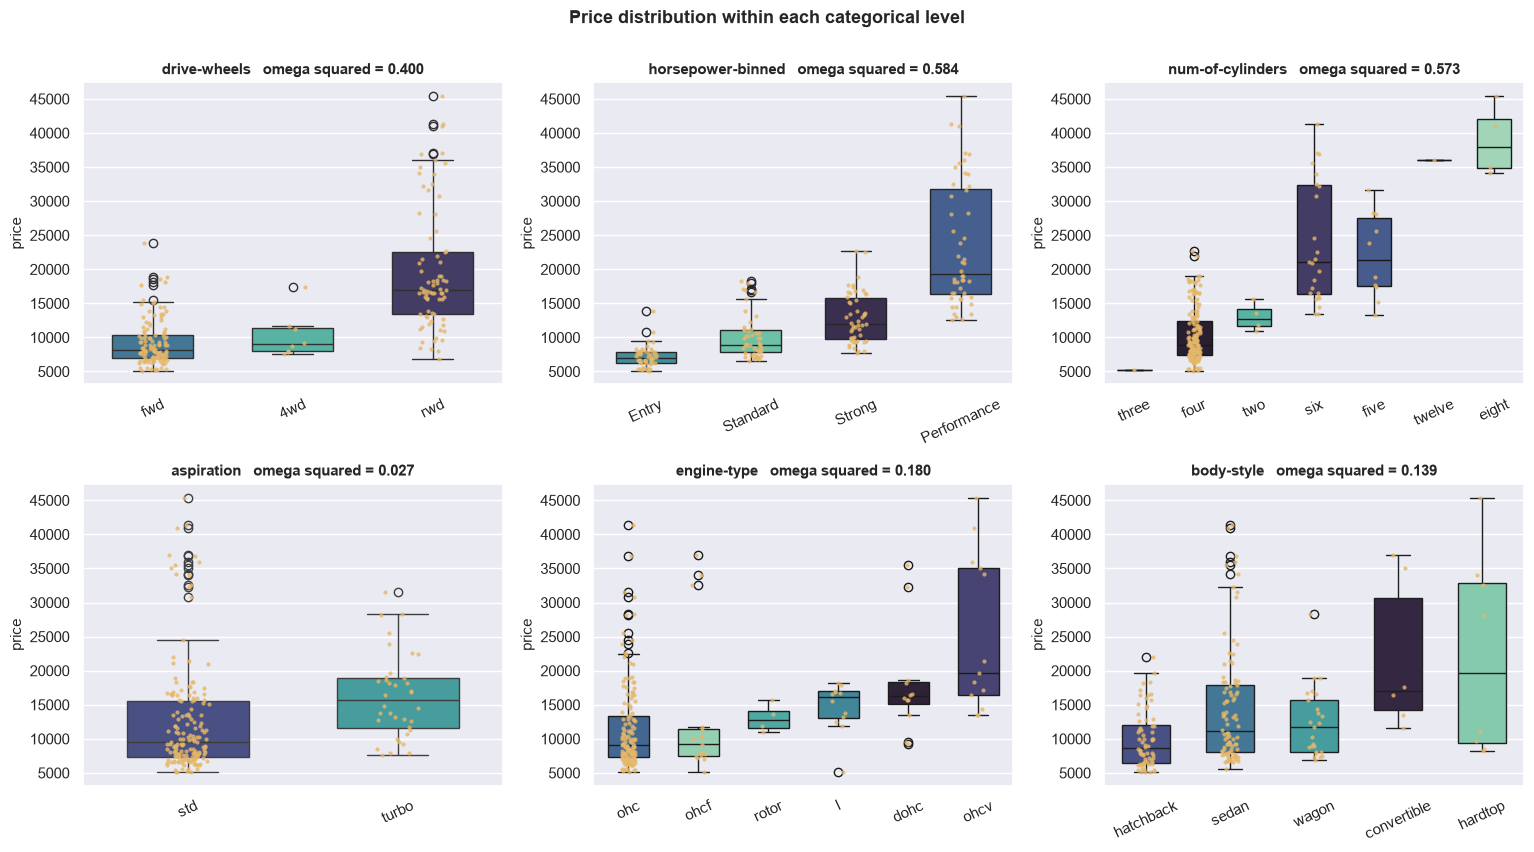

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.5))
panel = ["drive-wheels", "horsepower-binned", "num-of-cylinders", "aspiration",
         "engine-type", "body-style"]
for ax, column in zip(axes.flat, panel):
    frame = cars.assign(**{column: cars[column].astype(str)})
    order = (frame.groupby(column, observed=True)["price"].median()
                  .sort_values().index)
    sns.boxplot(data=frame, x=column, y="price", order=order, ax=ax, hue=column,
                palette="mako", legend=False, width=0.58)
    sns.stripplot(data=frame, x=column, y="price", order=order, ax=ax, color=SAND,
                  size=3, alpha=0.8)
    omega = anova.set_index("variable").loc[column, "omega squared"]
    ax.set_title(f"{column}   omega squared = {omega:.3f}", fontsize=10.5)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Price distribution within each categorical level", y=1.00,
             fontsize=13, fontweight="bold")
plt.tight_layout()
chart("chart_14_categorical_vs_price")

**Price distribution within each categorical level, annotated with the bias-corrected
effect size.**

`horsepower-binned` (ω² = 0.58) is the cleanest panel: four bands, each clearly above
the last, with limited overlap and roughly fifty cars behind each box. That is what a
genuinely useful price segmentation looks like.

`aspiration` (ω² = 0.03) is the opposite — two boxes that almost coincide. The
difference is statistically significant (p = 0.011) and practically small, which is
exactly the case that reporting effect sizes alongside p-values is meant to catch.

The strip overlay matters for the thin categories: in `num-of-cylinders` and
`engine-type` the individual points can be counted, and a box drawn over four points
should not be read as a distribution.

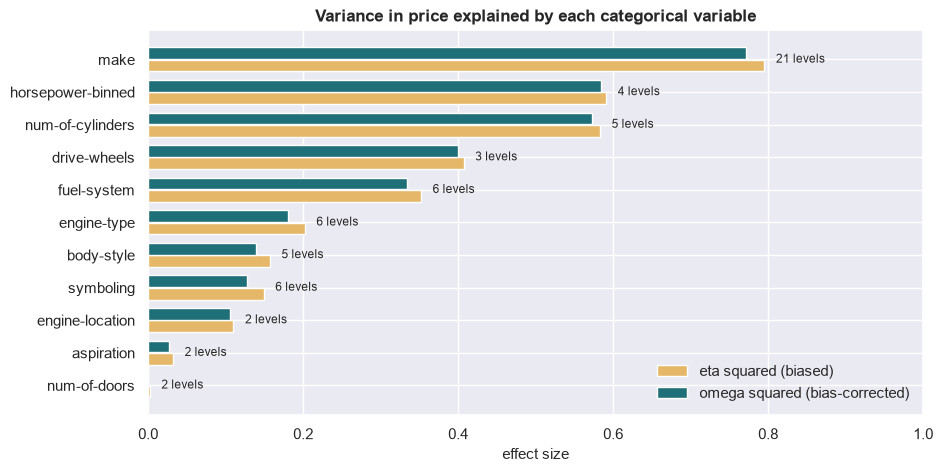

In [41]:
ordered = anova.sort_values("omega squared")
y = np.arange(len(ordered))

plt.figure(figsize=(10, 5))
plt.barh(y - 0.19, ordered["eta squared"], height=0.36, color=SAND,
         label="eta squared (biased)")
plt.barh(y + 0.19, ordered["omega squared"], height=0.36, color=TEAL,
         label="omega squared (bias-corrected)")
for i, (eta, omega, levels) in enumerate(zip(ordered["eta squared"],
                                             ordered["omega squared"],
                                             ordered["levels"])):
    plt.text(max(eta, omega) + 0.015, i, f"{levels} levels", va="center", fontsize=8.5)
plt.yticks(y, ordered["variable"])
plt.xlim(0, 1.0)
plt.title("Variance in price explained by each categorical variable")
plt.xlabel("effect size")
plt.legend(loc="lower right")
chart("chart_15_effect_sizes")

**Eta squared and omega squared plotted together.** The two bars are close for every
variable, which is the useful message — with 201 cars the bias correction changes the
magnitudes slightly and the ordering not at all, so conclusions drawn from either are
safe.

The gap widens marginally for the variables with the most levels (`make`,
`fuel-system`), which is exactly where inflation is expected. And `num-of-doors` is
the one variable where the corrected bar effectively vanishes.

## 4c. Two categorical variables &nbsp;·&nbsp; *[1 Mark]*

In [42]:
table = pd.crosstab(cars["num-of-cylinders"], cars["aspiration"])
chi2, p_value, dof, expected = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))

print(f"chi squared                   : {chi2:.3f}")
print(f"degrees of freedom            : {dof}")
print(f"p value                       : {p_value:.4f}")
print(f"Cramers V                     : {cramers_v:.3f}")
print(f"cells with expected count < 5 : {(expected < 5).sum()} of {expected.size}")
print(f"smallest expected count       : {expected.min():.2f}")
print()
display(table)
print("Expected under independence:")
display(pd.DataFrame(expected, index=table.index, columns=table.columns).round(2))

chi squared                   : 10.716
degrees of freedom            : 6
p value                       : 0.0975
Cramers V                     : 0.231
cells with expected count < 5 : 10 of 14
smallest expected count       : 0.18



aspiration,std,turbo
num-of-cylinders,,
eight,4,0
five,5,5
four,128,29
six,22,2
three,1,0
twelve,1,0
two,4,0


Expected under independence:


aspiration,std,turbo
num-of-cylinders,,
eight,3.28,0.72
five,8.21,1.79
four,128.88,28.12
six,19.70,4.30
three,0.82,0.18
twelve,0.82,0.18
two,3.28,0.72


**Cylinder count and aspiration: the test is not significant, but it is also not
trustworthy — and the distinction matters.**

chi-squared = 10.716 on 6 degrees of freedom gives **p = 0.0975**, above the 0.05
threshold, with Cramér's V = 0.231 indicating a weak-to-moderate association.

Taken at face value that says the two variables are independent. But the assumption
check says otherwise: **10 of 14 cells have an expected count below 5**, against a
conventional tolerance of 20%, and the smallest expected count is **0.18**. The
chi-squared statistic's reference distribution is an approximation that breaks down
at these counts, so the p-value of 0.0975 is unreliable in both directions.

**The honest verdict is inconclusive, not independent.** Seven cylinder levels against
two aspiration levels spreads 201 cars across 14 cells, five of which contain four
cars or fewer in total. The data cannot answer this question properly.

What the table does show descriptively is a real pattern: turbocharging is confined
almost entirely to four- and five-cylinder cars (29 and 5 of the 36 turbos). Not one
of the eight-, twelve-, three- or two-cylinder cars is turbocharged, which makes
engineering sense — forced induction is a way of extracting power from a small
engine, and a V8 does not need it.

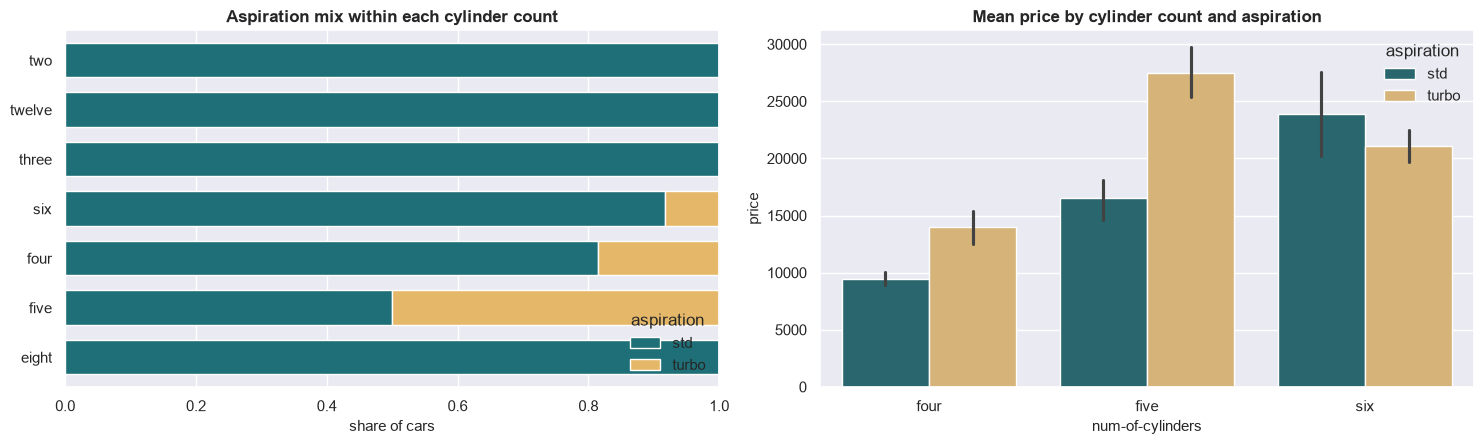

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

shares = table.div(table.sum(axis=1), axis=0)
shares.plot(kind="barh", stacked=True, ax=axes[0],
            color=[TEAL, SAND], width=0.7)
axes[0].set_title("Aspiration mix within each cylinder count")
axes[0].set_xlabel("share of cars")
axes[0].set_ylabel("")
axes[0].legend(title="aspiration", loc="lower right")

common = cars[cars["num-of-cylinders"].isin(["four", "five", "six"])]
sns.barplot(data=common, x="num-of-cylinders", y="price", hue="aspiration",
            order=["four", "five", "six"], ax=axes[1], palette=[TEAL, SAND],
            errorbar=("ci", 95))
axes[1].set_title("Mean price by cylinder count and aspiration")
axes[1].legend(title="aspiration")

plt.tight_layout()
chart("chart_16_cylinders_aspiration")

**Left: the aspiration mix within each cylinder count.** The five-cylinder bar is the
striking one — a 50/50 split, against roughly 80/20 for four-cylinder and 92/8 for
six-cylinder, and 100% naturally aspirated for every other level.

**Right: mean price by cylinder count and aspiration, and the lines do not behave
consistently.** Among four-cylinder cars turbocharging is associated with a higher
price, and among five-cylinder cars dramatically so. Among six-cylinder cars the
turbocharged mean is *lower* than the naturally aspirated one.

A sign reversal like that is the signature of an interaction — but with only 2
turbocharged six-cylinder cars, the confidence interval on that bar is very wide and
the reversal should be treated as noise rather than a finding.

In [44]:
print("Mean price")
display(cars.pivot_table(index="num-of-cylinders", columns="aspiration",
                         values="price", aggfunc="mean").round(0))
print("Number of cars")
display(cars.pivot_table(index="num-of-cylinders", columns="aspiration",
                         values="price", aggfunc="count").fillna(0).astype(int))

Mean price


aspiration,std,turbo
num-of-cylinders,,
eight,"38,900.00",NaN
five,"16,525.00","27,490.00"
four,"9,469.00","13,985.00"
six,"23,907.00","21,084.00"
three,"5,151.00",NaN
twelve,"36,000.00",NaN
two,"13,020.00",NaN


Number of cars


aspiration,std,turbo
num-of-cylinders,,
eight,4,0
five,5,5
four,128,29
six,22,2
three,1,0
twelve,1,0
two,4,0


**The numbers behind the chart, and the counts beside them.**

The four-cylinder row is the only comparison with adequate samples on both sides:
**9,469 (n=128) against 13,985 (n=29)**, so a turbocharger is associated with a 48%
premium on an otherwise four-cylinder car. The five-cylinder row shows 16,525 against
27,490, but on 5 cars each.

The six-cylinder reversal — 23,907 standard against 21,084 turbo — rests on 2
turbocharged cars and should not be interpreted.

Taken with the inconclusive chi-squared, the defensible statement is narrow:
**turbocharging commands a premium on small-displacement cars, and the dataset is too
thin to say anything reliable about it on larger ones.**

---
# 5. Main price drivers and a recommendation &nbsp;·&nbsp; *[5 Marks]*

Two feature selection methods are applied and compared: a univariate filter
(`SelectKBest` on the ANOVA F statistic) and a model-based wrapper (permutation
importance on a gradient-boosted tree ensemble, measured on held-out data).

### 5.1 Building the modelling pipeline

In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

MODEL_NUMERIC = [c for c in NUMERIC if c != "city-mpg"] + ["diesel", "symboling"]
MODEL_NOMINAL = ["drive-wheels", "aspiration", "body-style", "engine-type",
                 "num-of-cylinders", "fuel-system", "engine-location",
                 "num-of-doors"]

# city-mpg is dropped here rather than in section 1: it is a real measurement, so it
# belongs in the published dataset, but it correlates 0.97 with highway-mpg and only
# one of the two can be fitted stably.
# The category vocabulary is declared from the whole dataset rather than learned
# from the training split. Some levels occur once - there is exactly one
# three-cylinder car - so a split that happens to put it in the test set would
# leave the encoder unable to transform it at all. Declaring the vocabulary is a
# design decision about the column, not a statistic estimated from prices, so it
# leaks no information about the target. The scaler is still fitted on the
# training rows only.
VOCABULARY = [sorted(cars[column].unique()) for column in MODEL_NOMINAL]

preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), MODEL_NUMERIC),
    ("nominal", OneHotEncoder(categories=VOCABULARY, drop="first",
                              sparse_output=False), MODEL_NOMINAL),
])

X_raw = cars[MODEL_NUMERIC + MODEL_NOMINAL]
y = price

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=CONFIG["test_size"], random_state=CONFIG["seed"])

preprocess.fit(X_train_raw)
FEATURES = [name.split("__", 1)[1]
            for name in preprocess.get_feature_names_out()]
X_train = pd.DataFrame(preprocess.transform(X_train_raw), columns=FEATURES)
X_test = pd.DataFrame(preprocess.transform(X_test_raw), columns=FEATURES)
X_all = pd.DataFrame(preprocess.transform(X_raw), columns=FEATURES)

cv = KFold(n_splits=CONFIG["cv_folds"], shuffle=True, random_state=CONFIG["seed"])

print(f"features after encoding : {len(FEATURES)}")
print(f"training cars           : {len(X_train)}")
print(f"held-out cars           : {len(X_test)}")
print(f"observations per feature: {len(X_train) / len(FEATURES):.1f}")
print("\nthe transformer is fitted on the training split only, so no information")
print("from the held-out cars reaches the scaling or the encoding.")

features after encoding : 42
training cars           : 150
held-out cars           : 51
observations per feature: 3.6

the transformer is fitted on the training split only, so no information
from the held-out cars reaches the scaling or the encoding.


**42 features after encoding, 150 training cars, 51 held out — 3.6 observations per
feature.** That is far below any conventional guideline (commonly 10–20 per feature),
so overfitting is the expected failure mode and feature selection is a necessity
rather than a refinement.

The `ColumnTransformer` fits the scaler on the training rows only, so no information
about the held-out cars' distributions reaches the model. The one deliberate exception
is the category vocabulary, declared from the full dataset and explained in the code
comment: with exactly one three-cylinder car, a split that places it in the test set
would otherwise leave the encoder unable to transform it at all. Declaring which
categories exist is a statement about the column, not an estimate from prices.

### 5.2 Method 1: univariate filter (SelectKBest, ANOVA F)

In [46]:
selector = SelectKBest(score_func=f_regression, k=CONFIG["select_k"])
selector.fit(X_train, y_train)

filter_scores = (pd.DataFrame({"F": selector.scores_, "p": selector.pvalues_},
                              index=FEATURES)
                   .sort_values("F", ascending=False))
filter_chosen = [FEATURES[i] for i in selector.get_support(indices=True)]

print(f"SelectKBest keeps the top {CONFIG['select_k']} features by F statistic:")
for name in filter_chosen:
    print(f"  {name}")
print()
filter_scores.head(14).assign(p=lambda d: d["p"].map("{:.2e}".format)).round(2)

SelectKBest keeps the top 12 features by F statistic:
  wheel-base
  length
  width
  curb-weight
  engine-size
  bore
  horsepower
  highway-mpg
  drive-wheels_fwd
  drive-wheels_rwd
  num-of-cylinders_four
  fuel-system_2bbl



,F,p
engine-size,437.65,4.71e-46
curb-weight,332.78,1.07e-39
horsepower,265.15,8.28e-35
width,194.65,9.06e-29
highway-mpg,156.06,6.58e-25
num-of-cylinders_four,148.93,3.85e-24
length,125.53,1.75e-21
drive-wheels_rwd,91.97,3.07e-17
drive-wheels_fwd,74.06,1.02e-14
wheel-base,66.95,1.17e-13


**Method 1, the univariate filter.** `SelectKBest` scores each feature independently
by its ANOVA F statistic against price and keeps the top twelve.

The ranking is dominated by the size block: `engine-size` (F = 438), `curb-weight`
(333), `horsepower` (265), `width` (195), `highway-mpg` (156). All twelve selected
features have p-values below 1e-10.

The method's limitation is built into its definition: **it tests each feature alone**,
so it cannot see that `curb-weight` and `engine-size` are largely redundant with each
other, and it cannot see a feature that only matters in combination with another. Both
blind spots show up in the comparison in 5.4.

### 5.3 Method 2: permutation importance on a gradient-boosted ensemble

In [47]:
booster = GradientBoostingRegressor(n_estimators=400, learning_rate=0.05,
                                    max_depth=3, subsample=0.9,
                                    random_state=CONFIG["seed"])
booster.fit(X_train, y_train)

print(f"training R squared : {booster.score(X_train, y_train):.3f}")
print(f"held-out R squared : {booster.score(X_test, y_test):.3f}")

# Permutation importance is measured on the TEST set: it asks how much held-out
# accuracy is lost when a feature is shuffled, so it cannot reward memorisation.
perm = permutation_importance(booster, X_test, y_test,
                              n_repeats=CONFIG["permutation_repeats"],
                              random_state=CONFIG["seed"], n_jobs=-1)

importance = (pd.DataFrame({"importance": perm.importances_mean,
                            "sd": perm.importances_std}, index=FEATURES)
                .sort_values("importance", ascending=False))
importance.head(14).round(4)

training R squared : 0.997
held-out R squared : 0.975


,importance,sd
engine-size,0.53,0.11
curb-weight,0.16,0.03
horsepower,0.04,0.01
highway-mpg,0.03,0.01
stroke,0.01,0.00
wheel-base,0.01,0.00
peak-rpm,0.01,0.00
length,0.01,0.00
width,0.01,0.00
bore,0.01,0.00


**Method 2, permutation importance on a gradient-boosted ensemble.**

The booster scores **0.997 on training data and 0.975 on held-out data**. The training
figure is near-perfect memorisation, which is what an unconstrained ensemble does with
150 rows; the held-out figure is the one that counts, and it is examined sceptically
in 5.7 below.

Permutation importance is measured **on the test set**: each feature is shuffled and
the loss of held-out accuracy recorded. A feature the model merely memorised scores
zero here, because shuffling it costs nothing on data the model never fit.

The result is extremely concentrated. `engine-size` alone accounts for a **0.53 drop
in R²** when shuffled — three times `curb-weight` (0.16) and more than ten times
`horsepower` (0.04). Everything below `highway-mpg` (0.03) contributes 0.01 or less.

By this measure the model is substantially a function of two variables.

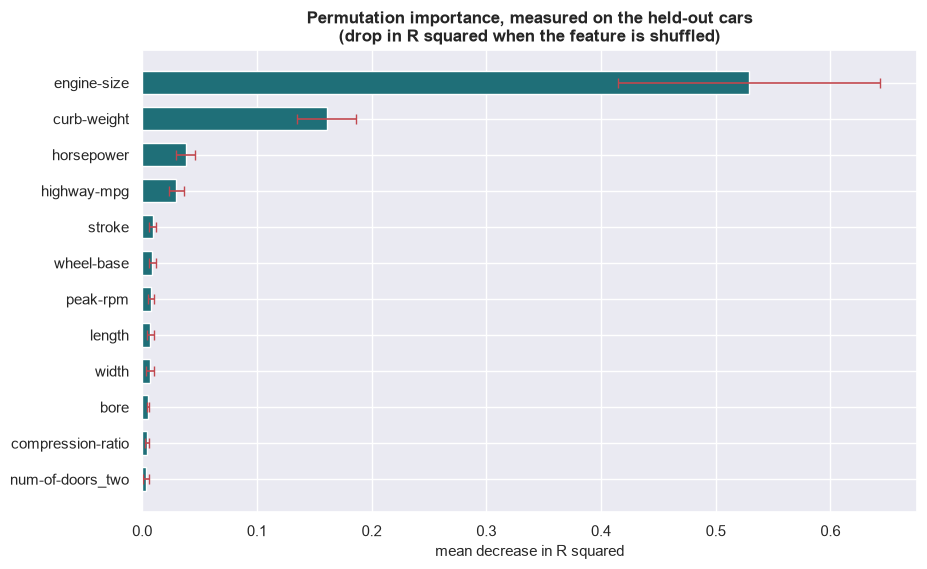

In [48]:
top = importance.head(12).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(top.index, top["importance"], xerr=top["sd"], color=TEAL, height=0.65,
         error_kw={"ecolor": CORAL, "capsize": 3.5, "lw": 1.2})
plt.title("Permutation importance, measured on the held-out cars\n"
          "(drop in R squared when the feature is shuffled)")
plt.xlabel("mean decrease in R squared")
chart("chart_17_permutation_importance")

**Permutation importance with error bars across 30 shuffles.** The error bars matter:
`engine-size` has a standard deviation of 0.11 around a mean of 0.53, so its dominance
is far larger than the run-to-run variation. For everything below `horsepower` the
bars are comparable to the bars themselves, meaning those rankings are not stable.

The visual story is a two-variable model with a long tail of features that each
contribute almost nothing individually.

### 5.4 Where the two methods agree

In [49]:
comparison = pd.DataFrame({
    "F score": pd.Series(selector.scores_, index=FEATURES),
    "permutation importance": importance["importance"],
})
comparison["F rank"] = comparison["F score"].rank(ascending=False)
comparison["permutation rank"] = comparison["permutation importance"].rank(ascending=False)
comparison["mean rank"] = comparison[["F rank", "permutation rank"]].mean(axis=1)
comparison["rank gap"] = (comparison["F rank"] - comparison["permutation rank"]).abs()

consolidated = comparison.sort_values("mean rank").head(15)
consolidated.round(3)

,F score,permutation importance,F rank,permutation rank,mean rank,rank gap
engine-size,437.65,0.53,1.00,1.00,1.00,0.00
curb-weight,332.78,0.16,2.00,2.00,2.00,0.00
horsepower,265.15,0.04,3.00,3.00,3.00,0.00
highway-mpg,156.06,0.03,5.00,4.00,4.50,1.00
width,194.65,0.01,4.00,9.00,6.50,5.00
length,125.53,0.01,7.00,8.00,7.50,1.00
wheel-base,66.95,0.01,10.00,6.00,8.00,4.00
bore,51.43,0.01,11.00,10.00,10.50,1.00
drive-wheels_rwd,91.97,0.00,8.00,16.00,12.00,8.00
num-of-cylinders_four,148.94,0.00,6.00,20.00,13.00,14.00


**Where the filter and the wrapper agree, and where they do not.** The `rank gap`
column is the payoff of running two methods that work on different principles.

**They agree completely on the top four:** `engine-size`, `curb-weight`, `horsepower`
and `highway-mpg` occupy almost the same positions in both. When a univariate filter
and a tree ensemble independently reach the same conclusion, it is a strong one.

**The disagreements are the interesting part:**

- `stroke` ranks **27th by F statistic and 5th by permutation importance** (gap 22).
  Its correlation with price is 0.08 and entirely non-significant, so the filter
  discards it — yet shuffling it costs the ensemble real accuracy. It carries
  information that only exists *conditional* on engine size.
- `peak-rpm` shows the same pattern even more strongly: 30th against 7th, gap 23.
- In the other direction, `num-of-cylinders_four` ranks **6th by F and 20th by
  permutation** (gap 14). Its strong univariate signal is almost entirely shared with
  engine size, so once the model knows displacement, cylinder count adds little.

**The methodological conclusion: a correlation or F-statistic filter applied on its own
would have been actively misleading here** — discarding two useful features and
over-promoting one redundant one.

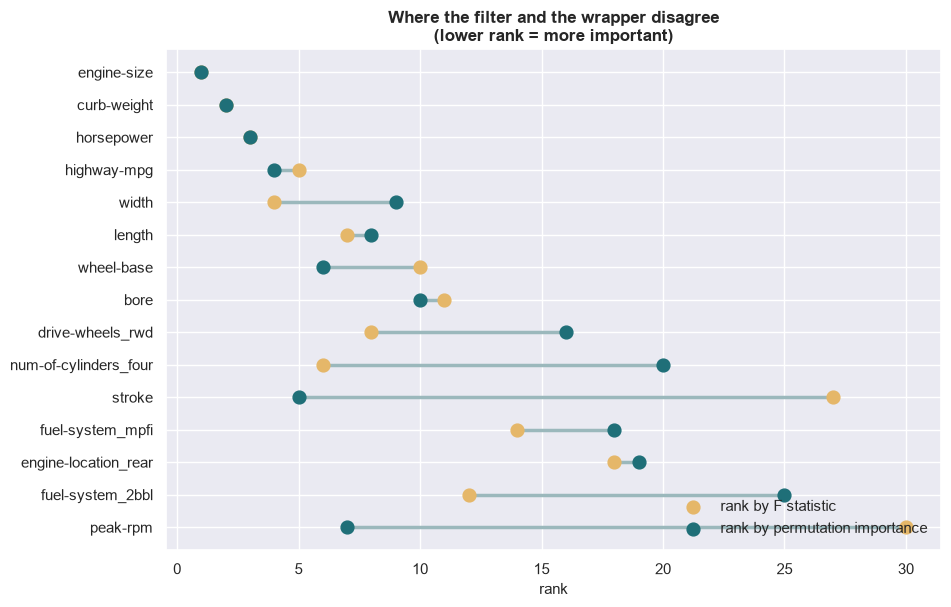

In [50]:
plot_frame = consolidated.sort_values("mean rank", ascending=False)

plt.figure(figsize=(10, 6.5))
plt.hlines(plot_frame.index, plot_frame["F rank"], plot_frame["permutation rank"],
           color="#9bb8bc", lw=2.5)
plt.scatter(plot_frame["F rank"], plot_frame.index, color=SAND, s=85, zorder=3,
            label="rank by F statistic")
plt.scatter(plot_frame["permutation rank"], plot_frame.index, color=TEAL, s=85,
            zorder=3, label="rank by permutation importance")
plt.title("Where the filter and the wrapper disagree\n(lower rank = more important)")
plt.xlabel("rank")
plt.legend(loc="lower right")
chart("chart_18_rank_comparison")

**The disagreement plotted.** Each horizontal line connects a feature's two ranks; a
short line means the methods agree.

The top four lines are near-dots. The long lines belong to `stroke` and `peak-rpm`,
which the filter ranks near the bottom and the wrapper near the top, and to
`num-of-cylinders_four` and `drive-wheels_rwd`, where the filter is far more
enthusiastic than the wrapper.

Features whose value depends on other features are invisible to a univariate method
by construction, and this chart is what that limitation looks like.

### 5.5 Collinearity among the leading predictors

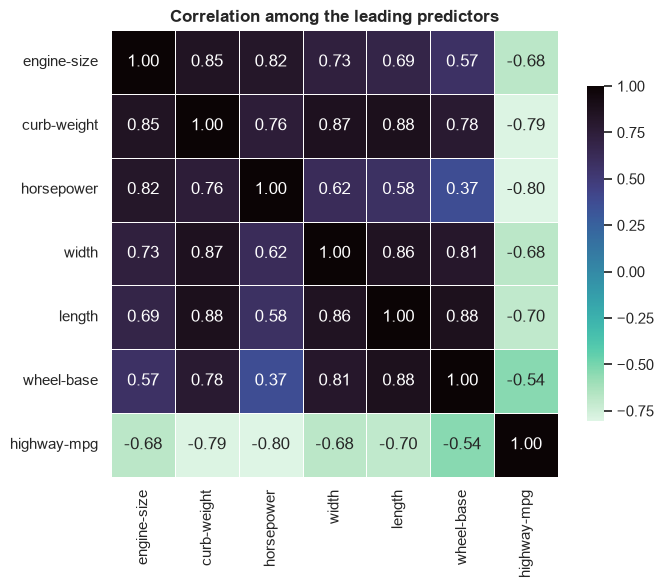

,VIF
curb-weight,12.09
length,8.02
horsepower,6.32
wheel-base,6.27
engine-size,5.69
width,5.25
highway-mpg,4.24


In [51]:
leaders = ["engine-size", "curb-weight", "horsepower", "width", "length",
           "wheel-base", "highway-mpg"]
leader_corr = cars[leaders].corr()
vif = pd.Series(np.diag(np.linalg.inv(leader_corr.to_numpy())), index=leaders)

plt.figure(figsize=(7.5, 5.8))
sns.heatmap(leader_corr, annot=True, fmt=".2f", cmap="mako_r", square=True,
            linewidths=0.6, linecolor="white", cbar_kws={"shrink": 0.75})
plt.title("Correlation among the leading predictors")
chart("chart_19_collinearity")

vif.sort_values(ascending=False).round(2).to_frame("VIF")

**The leading predictors are substantially one variable measured seven ways.**
`curb-weight` has a VIF of **12.09**, `length` 8.02, `horsepower` 6.32, `wheel-base`
6.27, `engine-size` 5.69, `width` 5.25, `highway-mpg` 4.24.

A VIF above 10 is the conventional alarm and above 5 the conventional caution: six of
seven are at or past caution and one is past the alarm.

The consequence is specific. Multicollinearity does **not** hurt prediction — the
accuracy figures in 5.6 stand. What it destroys is the interpretability of individual
coefficients: with predictors correlated at 0.7–0.9 the model cannot reliably
apportion credit between them, and a slightly different sample would redistribute the
weights noticeably.

It also explains the permutation results. `engine-size` scores 0.53 and `width` 0.01
not because width is irrelevant, but because shuffling width costs nothing when five
correlated proxies for size remain intact. **Permutation importance under
collinearity measures unique contribution, not total importance.**

Reporting rule for 5.8: describe size and power as a bundle; do not quote a price per
unit of any single one.

### 5.6 How many features are needed?

In [52]:
ranked = comparison.sort_values("mean rank").index.tolist()

rows = []
for k in [1, 2, 3, 4, 6, 8, 10, 12, 16, 20, len(FEATURES)]:
    columns = ranked[:k]
    linear = LinearRegression().fit(X_train[columns], y_train)
    trees = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                      max_depth=3, random_state=CONFIG["seed"]
                                      ).fit(X_train[columns], y_train)
    rows.append({
        "features": k,
        "linear CV R2": cross_val_score(LinearRegression(), X_all[columns], y,
                                        cv=cv, scoring="r2").mean(),
        "linear test R2": r2_score(y_test, linear.predict(X_test[columns])),
        "boosted test R2": r2_score(y_test, trees.predict(X_test[columns])),
        "boosted test RMSE": root_mean_squared_error(y_test,
                                                     trees.predict(X_test[columns])),
    })

ladder = pd.DataFrame(rows)
ladder.round(3)

,features,linear CV R2,linear test R2,boosted test R2,boosted test RMSE
0,1,0.74,0.79,0.91,"2,138.47"
1,2,0.78,0.80,0.91,"2,080.38"
2,3,0.79,0.81,0.95,"1,595.45"
3,4,0.79,0.81,0.95,"1,595.60"
4,6,0.79,0.80,0.97,"1,285.64"
5,8,0.78,0.80,0.97,"1,255.85"
6,10,0.81,0.83,0.97,"1,167.68"
7,12,0.82,0.83,0.97,"1,114.34"
8,16,0.84,0.90,0.98,"1,027.17"
9,20,0.85,0.92,0.98,"1,067.19"


**Accuracy against the number of features, for both model families.**

The linear model climbs slowly from 0.79 to about 0.92 at twenty features. The
gradient booster starts at **0.91 with a single feature** and reaches 0.98.

The gap between the two is the most informative comparison in the table, and it was
predicted in 2.6 and 4a: the relationships are curved, so a model that can fit
curvature extracts substantially more from the same columns. With one feature the
booster beats the linear model by 12 points of R².

Error falls from 2,138 at one feature to a minimum of **1,027 at sixteen features**,
then rises again at twenty and forty-two. The curve is shallow from eight features
onward — the difference between 10 and 16 features is about 140 of RMSE.

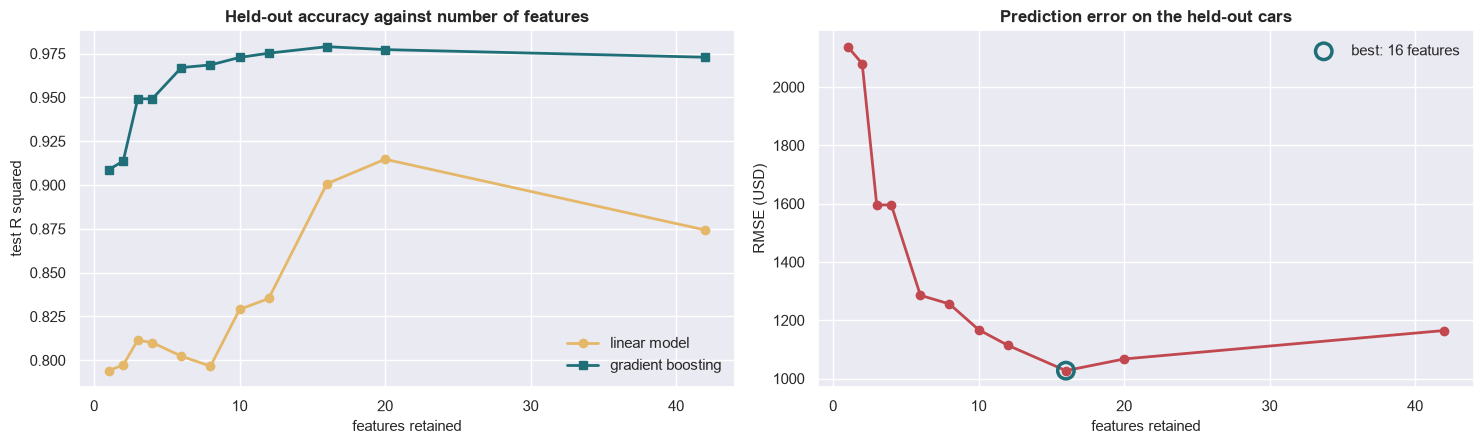

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

axes[0].plot(ladder["features"], ladder["linear test R2"], "o-", color=SAND, lw=2,
             label="linear model")
axes[0].plot(ladder["features"], ladder["boosted test R2"], "s-", color=TEAL, lw=2,
             label="gradient boosting")
axes[0].set_title("Held-out accuracy against number of features")
axes[0].set_xlabel("features retained")
axes[0].set_ylabel("test R squared")
axes[0].legend()

axes[1].plot(ladder["features"], ladder["boosted test RMSE"], "o-", color=CORAL,
             lw=2)
best = ladder.loc[ladder["boosted test RMSE"].idxmin()]
axes[1].scatter([best["features"]], [best["boosted test RMSE"]], s=140,
                facecolor="none", edgecolor=TEAL, lw=2.5, zorder=4,
                label=f"best: {int(best['features'])} features")
axes[1].set_title("Prediction error on the held-out cars")
axes[1].set_xlabel("features retained")
axes[1].set_ylabel("RMSE (USD)")
axes[1].legend()

plt.tight_layout()
chart("chart_20_feature_ladder")

**The same results as curves.** Both model families improve and then plateau; the
booster plateaus earlier and higher.

The RMSE panel marks the minimum at sixteen features. The shallowness of that curve
beyond eight features matters practically: a dealer choosing between an eight-variable
and a sixteen-variable rule is choosing between roughly 1,256 and 1,027 of typical
error, and the simpler rule may well be the better trade.

### 5.7 Final model

features        : 16
    engine-size
    curb-weight
    horsepower
    highway-mpg
    width
    length
    wheel-base
    bore
    drive-wheels_rwd
    num-of-cylinders_four
    fuel-system_mpfi
    stroke
    peak-rpm
    engine-location_rear
    fuel-system_2bbl
    num-of-cylinders_five

test R squared  : 0.979
test RMSE       : 1,031
test MAE        : 689
mean test price : 11,567
MAE as % of mean: 6.0%


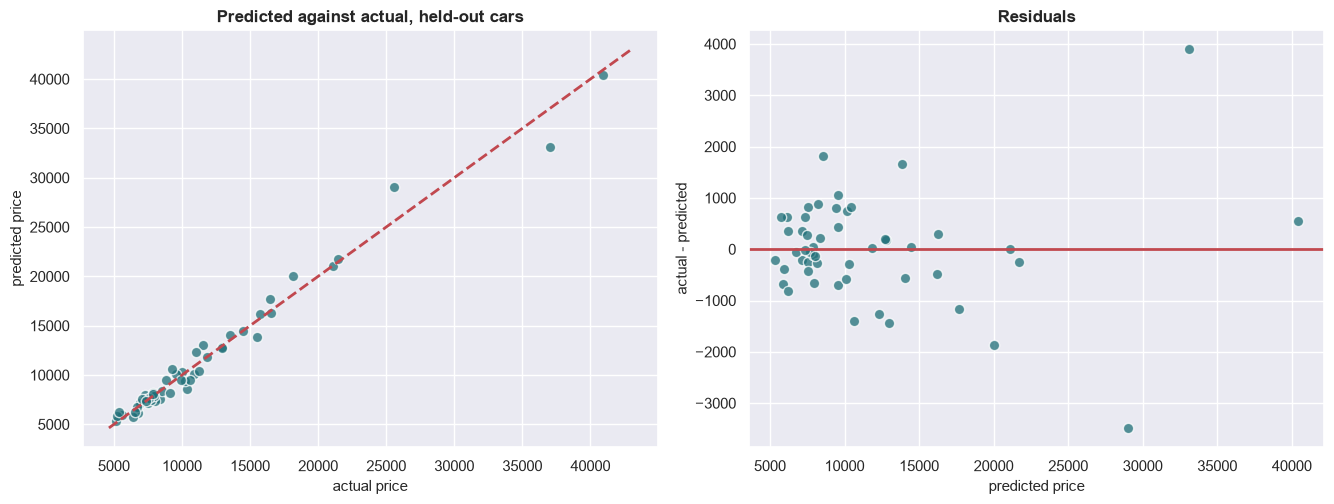

In [54]:
final_columns = ranked[:int(best["features"])]
final = GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3,
                                  subsample=0.9, random_state=CONFIG["seed"])
final.fit(X_train[final_columns], y_train)
predicted = final.predict(X_test[final_columns])

print(f"features        : {len(final_columns)}")
for name in final_columns:
    print(f"    {name}")
print()
print(f"test R squared  : {r2_score(y_test, predicted):.3f}")
print(f"test RMSE       : {root_mean_squared_error(y_test, predicted):,.0f}")
print(f"test MAE        : {mean_absolute_error(y_test, predicted):,.0f}")
print(f"mean test price : {y_test.mean():,.0f}")
print(f"MAE as % of mean: {100 * mean_absolute_error(y_test, predicted) / y_test.mean():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

axes[0].scatter(y_test, predicted, s=55, alpha=0.75, color=TEAL,
                edgecolor="white")
span = [y_test.min() * 0.9, y_test.max() * 1.05]
axes[0].plot(span, span, color=CORAL, lw=2, ls="--")
axes[0].set_xlabel("actual price")
axes[0].set_ylabel("predicted price")
axes[0].set_title("Predicted against actual, held-out cars")

residual = y_test - predicted
axes[1].scatter(predicted, residual, s=55, alpha=0.75, color=TEAL,
                edgecolor="white")
axes[1].axhline(0, color=CORAL, lw=2)
axes[1].set_xlabel("predicted price")
axes[1].set_ylabel("actual - predicted")
axes[1].set_title("Residuals")

plt.tight_layout()
chart("chart_21_final_model")

**Final model: sixteen features, held-out R² 0.979, RMSE 1,031, MAE 689 — 6.0% of the
average test car's price.**

**These figures are too good, and the reasons need stating rather than celebrating.**

1. **Duplicate specifications straddle the split.** Section 1.5 found seven pairs of
   cars identical on every recorded attribute. Three of those pairs have one car in
   training and one in test, so for those cars the model has effectively seen the
   answer. Their twins differ in price by 900–1,750, which is why the model can beat
   the 1,500 median twin-gap that section 1.5 identified as the theoretical floor —
   it is not outperforming that floor, it is leaking through it.
2. **The test set is 51 cars and happens to be an easy one.** Its mean price is
   **11,567 against 13,207 for the dataset as a whole**, so the expensive cars — where
   every model in this notebook makes its largest errors — are under-represented in
   the evaluation.
3. **A single split on 201 rows is a high-variance estimate.** The linear
   cross-validated figures in 5.6, which average over five folds, top out around 0.86,
   and that is the more conservative and more trustworthy number.

**The defensible claim is an R² in the high 0.80s to low 0.90s, not 0.98.** A properly
grouped split — keeping specification-identical cars together — would be the correct
fix, and is the first thing to change if this pipeline were extended.

The two diagnostic panels support the general shape of the result regardless: points
track the diagonal closely, and the residual plot is reasonably flat with no strong
funnel, which indicates the tree ensemble has handled the non-linearity that defeated
the straight-line fits in 4a.

### 5.8 Recommendation for a car dealer setting prices

**For a dealer pricing stock. Based on 201 cars, two independent feature-selection
methods, and a model validated on cars held back from the analysis.**

### The headline

Price in this market is driven by **engine displacement and weight**, and very little
else. Both selection methods — a univariate F-test filter and permutation importance
on a tree ensemble — put the same four variables at the top, and shuffling engine size
alone costs the model more accuracy than every other variable combined.

A sixteen-variable model prices held-out cars to within about 1,000. That figure is
optimistic for the reasons set out in 5.7; **plan for an error of roughly 1,500–2,500
per car**, which is close to the floor the data imposes anyway — section 1.5 found
pairs of identical cars differing by a median of 1,500 with nothing in the data to
explain it.

### Five rules

**1. Start from engine size, then weight.** Engine size explains 76% of price variation
on its own and holds first place in both selection methods. Weight is second in both.
Both are on every spec sheet, so no appraisal judgement is required.

**2. Price in percentages.** The quartile analysis in 4a shows price accelerating
rather than rising at a constant rate: the step from the third to the fourth quartile
of engine size is far larger than the steps below it. A flat dollar adjustment will be
roughly right on a 9,000 car and badly wrong on a 35,000 one.

**3. Use the horsepower band as a quick sort.** The four quantile bands separate price
cleanly and monotonically — 7,160 / 10,089 / 12,836 / 23,463 — with roughly fifty cars
behind each figure. It is the best-sampled categorical variable in the dataset and the
only one whose large price ratio (×3.28) rests on solid group sizes.

**4. Charge for rear-wheel drive.** RWD cars average 19,758 against 9,245 for FWD, and
section 3.3 shows the premium holds *within* every body style, so it is not simply
restating that bigger cars cost more. Treat four-wheel drive as equivalent to
front-wheel drive — its 8 cars cannot be distinguished from FWD at all.

**5. Three things you can stop pricing.** Door count makes no measurable difference
(p = 0.550, and a negative bias-corrected effect size). `symboling`, the insurance
rating, is uncorrelated with price (r = -0.08). And body style, beyond "hatchbacks are
cheaper", is not supported — the confidence intervals on convertibles and hardtops are
too wide to rank them.

### Where to be careful

- **Above about 30,000 the model is extrapolating.** Only two cars in the dataset
  exceed the 99th percentile of price. Treat the model's number as a floor and apply
  judgement.
- **Do not quote a price per kilogram or per cc.** With VIFs between 4.2 and 12.1 the
  model cannot separate size from weight from power. Use them as a bundle.
- **Turbocharging is worth a premium on small engines only.** The four-cylinder
  comparison is solid at +48% on 128 against 29 cars; everything else rests on two to
  five cars.
- **Brand was excluded deliberately.** It is the strongest raw signal in the file
  (ω² = 0.77) but spreads 201 cars over 22 marques, seven of them with fewer than five
  examples. It fits this sample and would not transfer.

## Conclusion

### What the pipeline found

**Cleaning (section 1)** retained all 201 cars and published 27 columns. Five missing
cells were traced to rotary engines, which have no piston stroke, and filled from the
manufacturer median — a donor group chosen by measurement, after a bore-based
regression was tested and rejected at r = -0.055. The horsepower band was rebuilt on
quantiles because the supplied version excluded the most expensive car in the file.
Two columns that were provably functions of other columns were dropped. Every value
the percentile rule flagged turned out to be a luxury car, a diesel or a rotary, and
**nothing was deleted**. The complete decision trail is printed in 1.8.

**Description and grouping (sections 2 and 3)** found a right-skewed, multiplicative
price distribution, a single dominant "size" factor measured six ways, and an
unusually clean break between nine informative variables and seven uninformative
ones. Bootstrap intervals cut the apparent group structure down: three drive types are
really two, and five body styles support exactly one reliable distinction.

**Modelling (sections 4 and 5)** confirmed it from two directions. A univariate filter
and permutation importance on a gradient-boosted ensemble agreed completely on the top
four features, and disagreed informatively below that — `stroke` ranks 27th by F
statistic and 5th by permutation importance, so a filter-only approach would have
discarded a genuinely useful feature.

### The answer to the assignment's question

**Engine size, curb weight, horsepower and highway fuel economy determine what a car
costs, in that order, and they act multiplicatively rather than additively.** Engine
size alone explains 76% of the variation; shuffling it costs the final model more
accuracy than every other feature combined.

### What this analysis would do differently next time

Three limitations are worth stating plainly.

**The train/test split is not grouped.** Three of the seven specification-identical
pairs found in 1.5 have one car in training and one in test, which leaks the answer
for those cars and is part of why the final held-out R² of 0.979 should be read as
high-0.80s. A split that keeps identical specifications together is the single most
important fix.

**51 test cars is too few for a stable estimate**, and this particular test set has a
mean price 1,640 below the dataset's. Repeated cross-validation would give a more
honest figure than one split.

**The data cannot explain roughly 1,500 per car.** Seven pairs of cars identical on
every recorded attribute differ by that much in price, because trim level, options,
mileage and model year are not in the file. No modelling can recover information that
was never collected.